In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ============================================================
# PROJECT PHASE 1 — FINAL RESULTS
# CELL 1: LOAD RAW RETRIEVAL EVIDENCE
# ============================================================

import os
import pandas as pd
import numpy as np

# Final results dataset
RESULTS_DIR = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

# Load RAW retrieval evidence
doctor_evidence = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "doctor_facing_retrieval_evidence.csv"
    )
)

print("=" * 70)
print("RAW RETRIEVAL EVIDENCE LOADED")
print("=" * 70)

print("\nShape:", doctor_evidence.shape)

print("\nColumns:")
print(doctor_evidence.columns.tolist())

print("\nUnique test images:",
      doctor_evidence["Test_Image_Key"].nunique())

print("\nRetrieval rows:",
      len(doctor_evidence))

print("\nFirst 5 rows:")
display(doctor_evidence.head())

RAW RETRIEVAL EVIDENCE LOADED

Shape: (2010, 8)

Columns:
['Test_Image_Key', 'RETFound_Prediction', 'Rank', 'Retrieved_Image_Key', 'Similarity', 'Retrieved_Labels', 'Supporting_Labels', 'Support_Status']

Unique test images: 402

Retrieval rows: 2010

First 5 rows:


,Test_Image_Key,RETFound_Prediction,Rank,Retrieved_Image_Key,Similarity,Retrieved_Labels,Supporting_Labels,Support_Status
0,Training_3,DR,1,Training_38,0.979671,DR,DR,Supports
1,Training_3,DR,2,Training_976,0.973495,DR,DR,Supports
2,Training_3,DR,3,Training_263,0.971075,DR,DR,Supports
3,Training_3,DR,4,Training_1384,0.967998,DR,DR,Supports
4,Training_3,DR,5,Training_1394,0.966088,DR,DR,Supports


In [2]:
# ============================================================
# CELL 2: VERIFY RAW RETRIEVAL STRUCTURE
# ============================================================

print("=" * 70)
print("RAW RETRIEVAL DATA VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Retrieval count for every test image
# ------------------------------------------------------------

retrieval_counts = (
    doctor_evidence
    .groupby("Test_Image_Key")
    .size()
)

print("\nRetrieval count per image:")
print(retrieval_counts.value_counts().sort_index())

# ------------------------------------------------------------
# 2. Rank distribution
# ------------------------------------------------------------

print("\nRank distribution:")
print(
    doctor_evidence["Rank"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 3. Check that every image has ranks 1–5
# ------------------------------------------------------------

expected_ranks = {1, 2, 3, 4, 5}

invalid_rank_images = []

for image_key, group in doctor_evidence.groupby("Test_Image_Key"):
    ranks = set(group["Rank"].tolist())

    if ranks != expected_ranks:
        invalid_rank_images.append(
            (image_key, ranks)
        )

print("\nImages with invalid rank sets:",
      len(invalid_rank_images))

# ------------------------------------------------------------
# 4. Similarity validity
# ------------------------------------------------------------

invalid_similarity = doctor_evidence[
    (doctor_evidence["Similarity"] < -1) |
    (doctor_evidence["Similarity"] > 1) |
    (doctor_evidence["Similarity"].isna())
]

print("\nInvalid similarity values:",
      len(invalid_similarity))

print("\nSimilarity range:")
print(
    doctor_evidence["Similarity"].min(),
    "to",
    doctor_evidence["Similarity"].max()
)

# ------------------------------------------------------------
# 5. Prediction consistency within each image
# ------------------------------------------------------------

prediction_counts = (
    doctor_evidence
    .groupby("Test_Image_Key")["RETFound_Prediction"]
    .nunique()
)

inconsistent_predictions = prediction_counts[
    prediction_counts > 1
]

print("\nImages with inconsistent RETFound predictions:",
      len(inconsistent_predictions))

# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)

if (
    len(invalid_rank_images) == 0
    and len(invalid_similarity) == 0
    and len(inconsistent_predictions) == 0
    and retrieval_counts.eq(5).all()
):
    print("RAW RETRIEVAL DATA: VERIFIED ✓")
else:
    print("RAW RETRIEVAL DATA: CHECK REQUIRED")

print("=" * 70)

RAW RETRIEVAL DATA VERIFICATION

Retrieval count per image:
5    402
Name: count, dtype: int64

Rank distribution:
Rank
1    402
2    402
3    402
4    402
5    402
Name: count, dtype: int64

Images with invalid rank sets: 0

Invalid similarity values: 0

Similarity range:
0.6386971473693848 to 0.9945052862167358

Images with inconsistent RETFound predictions: 0

RAW RETRIEVAL DATA: VERIFIED ✓


In [3]:
# ============================================================
# CELL 3: CALCULATE EVIDENCE SUPPORT FROM SCRATCH
# ============================================================

evidence_results = []

for image_key, group in doctor_evidence.groupby("Test_Image_Key"):

    # Keep retrievals in rank order
    group = group.sort_values("Rank").reset_index(drop=True)

    # --------------------------------------------------------
    # RETFound prediction
    # --------------------------------------------------------
    prediction = group["RETFound_Prediction"].iloc[0]

    predicted_labels = [
        label.strip()
        for label in str(prediction).split(",")
        if label.strip()
    ]

    # --------------------------------------------------------
    # Similarities of the 5 retrieved images
    # --------------------------------------------------------
    similarities = group["Similarity"].astype(float).values

    # Denominator:
    # total similarity of all 5 retrieved images
    total_similarity = similarities.sum()

    # --------------------------------------------------------
    # Calculate support for each predicted label
    # --------------------------------------------------------
    label_supports = {}
    label_case_counts = {}

    for label in predicted_labels:

        supporting_similarity = 0.0
        supporting_cases = 0

        for _, row in group.iterrows():

            retrieved_labels = [
                x.strip()
                for x in str(row["Retrieved_Labels"]).split(",")
                if x.strip()
            ]

            # Does this retrieved image support the
            # predicted label?
            if label in retrieved_labels:

                supporting_similarity += float(
                    row["Similarity"]
                )

                supporting_cases += 1

        # ----------------------------------------------------
        # Similarity-weighted label support
        # ----------------------------------------------------
        label_support = (
            supporting_similarity /
            total_similarity
        ) * 100

        label_supports[label] = label_support
        label_case_counts[label] = supporting_cases

    # --------------------------------------------------------
    # Overall evidence support
    #
    # For multi-label prediction:
    # average the support of each predicted label
    # --------------------------------------------------------
    evidence_support = np.mean(
        list(label_supports.values())
    )

    # --------------------------------------------------------
    # Mean similarity of the 5 retrieved images
    # --------------------------------------------------------
    mean_similarity = similarities.mean() * 100

    # --------------------------------------------------------
    # Supporting retrieval cases
    #
    # Number of the 5 retrieved images that support
    # at least one predicted label
    # --------------------------------------------------------
    supporting_cases_total = 0

    for _, row in group.iterrows():

        retrieved_labels = [
            x.strip()
            for x in str(row["Retrieved_Labels"]).split(",")
            if x.strip()
        ]

        if any(
            label in retrieved_labels
            for label in predicted_labels
        ):
            supporting_cases_total += 1

    # --------------------------------------------------------
    # Evidence strength
    # --------------------------------------------------------
    if evidence_support >= 80:
        evidence_strength = "HIGH"

    elif evidence_support >= 60:
        evidence_strength = "MODERATE"

    else:
        evidence_strength = "LOW"

    # --------------------------------------------------------
    # Store result
    # --------------------------------------------------------
    evidence_results.append({

        "Test_Image_Key": image_key,

        "RETFound_Prediction": prediction,

        "Supporting_Cases":
            f"{supporting_cases_total}/5",

        "Total_Retrieved":
            len(group),

        "Evidence_Support_%":
            round(evidence_support, 2),

        "Mean_Similarity_%":
            round(mean_similarity, 2),

        "Evidence_Strength":
            evidence_strength
    })


# ============================================================
# CREATE FINAL SUMMARY DATAFRAME
# ============================================================

final_evidence_summary = pd.DataFrame(
    evidence_results
)

final_evidence_summary = (
    final_evidence_summary
    .sort_values("Test_Image_Key")
    .reset_index(drop=True)
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("=" * 70)
print("EVIDENCE SUPPORT CALCULATION COMPLETE")
print("=" * 70)

print("\nNumber of test images:",
      len(final_evidence_summary))

print("\nEvidence Support range:")
print(
    final_evidence_summary["Evidence_Support_%"].min(),
    "to",
    final_evidence_summary["Evidence_Support_%"].max()
)

print("\nMean Similarity range:")
print(
    final_evidence_summary["Mean_Similarity_%"].min(),
    "to",
    final_evidence_summary["Mean_Similarity_%"].max()
)

print("\nEvidence Strength distribution:")
print(
    final_evidence_summary["Evidence_Strength"]
    .value_counts()
)

print("\nFirst 10 results:")
display(final_evidence_summary.head(10))

EVIDENCE SUPPORT CALCULATION COMPLETE

Number of test images: 402

Evidence Support range:
0.0 to 100.0

Mean Similarity range:
64.62 to 99.25

Evidence Strength distribution:
Evidence_Strength
HIGH        338
MODERATE     32
LOW          32
Name: count, dtype: int64

First 10 results:


,Test_Image_Key,RETFound_Prediction,Supporting_Cases,Total_Retrieved,Evidence_Support_%,Mean_Similarity_%,Evidence_Strength
0,Testing_1,"DR, ODC, TSLN",5/5,5,66.67,80.60,MODERATE
1,Testing_100,DR,5/5,5,100.00,81.71,HIGH
2,Testing_108,MH,5/5,5,100.00,97.02,HIGH
3,Testing_112,DR,5/5,5,100.00,97.21,HIGH
4,Testing_115,DR,5/5,5,100.00,96.50,HIGH
5,Testing_139,"TSLN, DN, ODP",5/5,5,73.26,73.34,MODERATE
6,Testing_141,DR,5/5,5,100.00,97.18,HIGH
7,Testing_147,DR,5/5,5,100.00,96.77,HIGH
8,Testing_148,DR,5/5,5,100.00,96.00,HIGH
9,Testing_157,"ODC, MYA",5/5,5,50.00,91.57,LOW


In [4]:
# ============================================================
# CELL 4: MANUAL VERIFICATION OF A MIXED MULTI-LABEL CASE
# ============================================================

CASE_IMAGE = "Testing_1"

case = doctor_evidence[
    doctor_evidence["Test_Image_Key"] == CASE_IMAGE
].sort_values("Rank").copy()

prediction = case["RETFound_Prediction"].iloc[0]

predicted_labels = [
    x.strip()
    for x in str(prediction).split(",")
    if x.strip()
]

similarities = case["Similarity"].astype(float).values

total_similarity = similarities.sum()

print("=" * 80)
print("MANUAL EVIDENCE VERIFICATION")
print("=" * 80)

print("\nTest Image:", CASE_IMAGE)
print("RETFound Prediction:", predicted_labels)

print("\nRetrieved cases:")
print("-" * 80)

for _, row in case.iterrows():

    print(
        f"Rank {int(row['Rank'])} | "
        f"{row['Retrieved_Image_Key']} | "
        f"Similarity = {row['Similarity']:.6f} | "
        f"Labels = {row['Retrieved_Labels']}"
    )

print("\nTotal similarity:")
print(f"{total_similarity:.6f}")

# ------------------------------------------------------------
# Calculate each predicted label
# ------------------------------------------------------------

label_supports = []

for label in predicted_labels:

    supporting_images = []
    supporting_similarity = 0.0

    for _, row in case.iterrows():

        retrieved_labels = [
            x.strip()
            for x in str(row["Retrieved_Labels"]).split(",")
            if x.strip()
        ]

        if label in retrieved_labels:

            supporting_images.append(
                row["Retrieved_Image_Key"]
            )

            supporting_similarity += float(
                row["Similarity"]
            )

    support = (
        supporting_similarity /
        total_similarity
    ) * 100

    label_supports.append(support)

    print("\n" + "-" * 80)
    print(f"Predicted label: {label}")

    print(
        "Supporting retrieved images:",
        supporting_images
    )

    print(
        f"Supporting similarity = "
        f"{supporting_similarity:.6f}"
    )

    print(
        f"Support calculation = "
        f"{supporting_similarity:.6f} / "
        f"{total_similarity:.6f} × 100"
    )

    print(
        f"Label support = {support:.6f}%"
    )

# ------------------------------------------------------------
# Overall evidence support
# ------------------------------------------------------------

overall_support = np.mean(label_supports)

print("\n" + "=" * 80)
print("FINAL CALCULATION")
print("=" * 80)

for label, support in zip(predicted_labels, label_supports):
    print(f"{label}: {support:.6f}%")

print(
    "\nEvidence Support = "
    f"({' + '.join(f'{x:.6f}' for x in label_supports)}) "
    f"/ {len(label_supports)}"
)

print(
    f"\nOverall Evidence Support = "
    f"{overall_support:.6f}%"
)

# Compare with newly calculated summary
saved_value = final_evidence_summary.loc[
    final_evidence_summary["Test_Image_Key"] == CASE_IMAGE,
    "Evidence_Support_%"
].iloc[0]

print(
    f"Summary value = {saved_value:.2f}%"
)

print(
    f"Difference = "
    f"{abs(overall_support - saved_value):.6f}%"
)

MANUAL EVIDENCE VERIFICATION

Test Image: Testing_1
RETFound Prediction: ['DR', 'ODC', 'TSLN']

Retrieved cases:
--------------------------------------------------------------------------------
Rank 1 | Validation_168 | Similarity = 0.816652 | Labels = DR, TSLN
Rank 2 | Training_427 | Similarity = 0.813435 | Labels = DR, TSLN
Rank 3 | Training_1127 | Similarity = 0.801808 | Labels = DR, TSLN
Rank 4 | Training_426 | Similarity = 0.801379 | Labels = DR, TSLN
Rank 5 | Training_556 | Similarity = 0.796919 | Labels = DR, TSLN

Total similarity:
4.030193

--------------------------------------------------------------------------------
Predicted label: DR
Supporting retrieved images: ['Validation_168', 'Training_427', 'Training_1127', 'Training_426', 'Training_556']
Supporting similarity = 4.030193
Support calculation = 4.030193 / 4.030193 × 100
Label support = 100.000000%

--------------------------------------------------------------------------------
Predicted label: ODC
Supporting retriev

In [5]:
# ============================================================
# CELL 5: SAVE CORRECTED FINAL EVIDENCE SUMMARY
# ============================================================

FINAL_RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS"

os.makedirs(FINAL_RESULTS_DIR, exist_ok=True)

# Save corrected evidence summary
summary_path = os.path.join(
    FINAL_RESULTS_DIR,
    "doctor_facing_retrieval_summary.csv"
)

final_evidence_summary.to_csv(
    summary_path,
    index=False
)

print("=" * 70)
print("CORRECTED SUMMARY SAVED")
print("=" * 70)

print("\nFile:")
print(summary_path)

print("\nShape:")
print(final_evidence_summary.shape)

print("\nExample corrected cases:")

example_cases = [
    "Training_488",
    "Training_628",
    "Training_1391",
    "Training_1615",
    "Training_1431",
    "Testing_1",
    "Training_1373"
]

display(
    final_evidence_summary[
        final_evidence_summary["Test_Image_Key"].isin(example_cases)
    ]
    .sort_values("Test_Image_Key")
)

CORRECTED SUMMARY SAVED

File:
/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS/doctor_facing_retrieval_summary.csv

Shape:
(402, 7)

Example corrected cases:


,Test_Image_Key,RETFound_Prediction,Supporting_Cases,Total_Retrieved,Evidence_Support_%,Mean_Similarity_%,Evidence_Strength
0,Testing_1,"DR, ODC, TSLN",5/5,5,66.67,80.60,MODERATE
128,Training_1373,"DR, TSLN",5/5,5,100.00,94.43,HIGH
133,Training_1391,"DR, MH",5/5,5,80.16,89.69,HIGH
142,Training_1431,"TSLN, BRVO",5/5,5,90.41,90.09,HIGH
158,Training_1615,"DR, MH",5/5,5,70.23,89.81,MODERATE
247,Training_488,"ODC, ARMD, MYA",5/5,5,46.70,76.52,LOW
262,Training_628,"ODC, ARMD, MYA",5/5,5,66.67,92.96,MODERATE


In [6]:
# ============================================================
# CELL 6: FINAL VERIFICATION OF CORRECTED SUMMARY
# ============================================================

# Recalculate directly from raw retrieval evidence
# and compare with final_evidence_summary.

verification = []

for image_key, group in doctor_evidence.groupby("Test_Image_Key"):

    group = group.sort_values("Rank").reset_index(drop=True)

    prediction = group["RETFound_Prediction"].iloc[0]

    predicted_labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    similarities = group["Similarity"].astype(float).values

    total_similarity = similarities.sum()

    # -----------------------------
    # Mean similarity
    # -----------------------------
    calculated_mean_similarity = (
        similarities.mean() * 100
    )

    # -----------------------------
    # Evidence support
    # -----------------------------
    label_supports = []

    for label in predicted_labels:

        supporting_similarity = 0.0

        for _, row in group.iterrows():

            retrieved_labels = [
                x.strip()
                for x in str(row["Retrieved_Labels"]).split(",")
                if x.strip()
            ]

            if label in retrieved_labels:
                supporting_similarity += float(
                    row["Similarity"]
                )

        label_support = (
            supporting_similarity /
            total_similarity
        ) * 100

        label_supports.append(label_support)

    calculated_evidence_support = np.mean(
        label_supports
    )

    verification.append({
        "Test_Image_Key": image_key,
        "Calculated_Evidence_Support_%":
            calculated_evidence_support,
        "Saved_Evidence_Support_%":
            final_evidence_summary.loc[
                final_evidence_summary["Test_Image_Key"]
                == image_key,
                "Evidence_Support_%"
            ].iloc[0],
        "Calculated_Mean_Similarity_%":
            calculated_mean_similarity,
        "Saved_Mean_Similarity_%":
            final_evidence_summary.loc[
                final_evidence_summary["Test_Image_Key"]
                == image_key,
                "Mean_Similarity_%"
            ].iloc[0]
    })


verification_df = pd.DataFrame(verification)

# ------------------------------------------------------------
# Differences
# ------------------------------------------------------------

verification_df["Evidence_Difference"] = (
    verification_df[
        "Calculated_Evidence_Support_%"
    ]
    - verification_df[
        "Saved_Evidence_Support_%"
    ]
).abs()

verification_df["Mean_Similarity_Difference"] = (
    verification_df[
        "Calculated_Mean_Similarity_%"
    ]
    - verification_df[
        "Saved_Mean_Similarity_%"
    ]
).abs()


# ============================================================
# RESULTS
# ============================================================

print("=" * 75)
print("FINAL SUMMARY VERIFICATION")
print("=" * 75)

print("\nImages verified:",
      len(verification_df))

print("\n--- EVIDENCE SUPPORT ---")

print(
    "Maximum difference:",
    f"{verification_df['Evidence_Difference'].max():.10f}%"
)

print(
    "Cases > 0.01%:",
    (verification_df["Evidence_Difference"] > 0.01).sum()
)

print(
    "Cases > 0.1%:",
    (verification_df["Evidence_Difference"] > 0.1).sum()
)

print("\n--- MEAN SIMILARITY ---")

print(
    "Maximum difference:",
    f"{verification_df['Mean_Similarity_Difference'].max():.10f}%"
)

print(
    "Cases > 0.01%:",
    (verification_df["Mean_Similarity_Difference"] > 0.01).sum()
)

print(
    "Cases > 0.1%:",
    (verification_df["Mean_Similarity_Difference"] > 0.1).sum()
)


# ============================================================
# FINAL STATUS
# ============================================================

evidence_ok = (
    verification_df["Evidence_Difference"] <= 0.01
).all()

similarity_ok = (
    verification_df["Mean_Similarity_Difference"] <= 0.01
).all()

print("\n" + "=" * 75)

if evidence_ok and similarity_ok:
    print("FINAL SUMMARY: VERIFIED ✓")
    print("All 402 evidence-support calculations are correct.")
    print("All 402 mean-similarity calculations are correct.")
else:
    print("FINAL SUMMARY: CHECK REQUIRED")

print("=" * 75)


# ============================================================
# SHOW THE SIX CASES
# ============================================================

six_cases = [
    "Testing_562",
    "Training_1373",
    "Training_1431",
    "Training_1391",
    "Training_1615",
    "Training_628"
]

print("\nSix demonstration cases:")
display(
    final_evidence_summary[
        final_evidence_summary["Test_Image_Key"]
        .isin(six_cases)
    ]
)

FINAL SUMMARY VERIFICATION

Images verified: 402

--- EVIDENCE SUPPORT ---
Maximum difference: 0.0049331665%
Cases > 0.01%: 0
Cases > 0.1%: 0

--- MEAN SIMILARITY ---
Maximum difference: 0.0049993134%
Cases > 0.01%: 0
Cases > 0.1%: 0

FINAL SUMMARY: VERIFIED ✓
All 402 evidence-support calculations are correct.
All 402 mean-similarity calculations are correct.

Six demonstration cases:


,Test_Image_Key,RETFound_Prediction,Supporting_Cases,Total_Retrieved,Evidence_Support_%,Mean_Similarity_%,Evidence_Strength
58,Testing_562,Is_Normal,5/5,5,100.00,99.25,HIGH
128,Training_1373,"DR, TSLN",5/5,5,100.00,94.43,HIGH
133,Training_1391,"DR, MH",5/5,5,80.16,89.69,HIGH
142,Training_1431,"TSLN, BRVO",5/5,5,90.41,90.09,HIGH
158,Training_1615,"DR, MH",5/5,5,70.23,89.81,MODERATE
262,Training_628,"ODC, ARMD, MYA",5/5,5,66.67,92.96,MODERATE


In [7]:
# ============================================================
# CELL 7: CREATE FINAL RESULTS PACKAGE
# ============================================================

import os
import shutil
import json

FINAL_RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS"

os.makedirs(FINAL_RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Corrected retrieval summary
# ------------------------------------------------------------

final_evidence_summary.to_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_retrieval_summary.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 2. Raw retrieval evidence
# ------------------------------------------------------------

doctor_evidence.to_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_retrieval_evidence.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 3. Copy other verified result files from the
#    existing Kaggle final-results dataset
# ------------------------------------------------------------

files_to_copy = [
    "final_classification_thresholds.json",
    "final_test_classification_metrics.json",
    "per_class_test_metrics.csv",
    "test_metrics.json",
    "test_top5_retrieval_with_labels.csv",
    "top5_retrieval_label_agreement.csv",
    "per_class_top5_retrieval_agreement.csv",
    "top5_retrieval_agreement_metrics.json",
    "per_class_retrieval_support.csv",
    "final_retrieval_evidence_metrics.json",
    "labelwise_retrieval_evidence.csv",
    "optimal_thresholds.json"
]

for filename in files_to_copy:

    source = os.path.join(
        RESULTS_DIR,
        filename
    )

    destination = os.path.join(
        FINAL_RESULTS_DIR,
        filename
    )

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("WARNING — not found:", filename)

# ------------------------------------------------------------
# 4. Create a README describing the corrected calculation
# ------------------------------------------------------------

readme_text = """
PROJECT PHASE 1 — RETFound Final Results

This folder contains the final classification and
retrieval-evidence results for the modified RFMiD dataset.

IMPORTANT:
The retrieval evidence summary was independently recalculated
from the raw Top-5 retrieval records.

Evidence Support calculation:

For each predicted label l:

Support(l) =
    sum(S_i * I_i,l) / sum(S_i) * 100

where:
    S_i     = cosine similarity of retrieved image i
    I_i,l   = 1 if retrieved image i contains label l,
              otherwise 0.

For multi-label predictions:

Evidence Support =
    average of the support percentages
    across all predicted labels.

Mean Similarity:

Mean Similarity =
    mean of the five cosine similarities * 100.

Verification:
- 402 test images independently verified.
- Each test image has exactly 5 retrieved images.
- Ranks 1–5 are complete.
- All similarity values are valid.
- Evidence Support maximum verification difference: < 0.01%.
- Mean Similarity maximum verification difference: < 0.01%.

The retrieval evidence is supporting visual evidence and is
not fused with the RETFound classifier probabilities.
"""

with open(
    os.path.join(FINAL_RESULTS_DIR, "README.txt"),
    "w"
) as f:
    f.write(readme_text)

print("\nREADME created.")

# ------------------------------------------------------------
# 5. List final files
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL RESULTS PACKAGE")
print("=" * 70)

final_files = sorted(
    os.listdir(FINAL_RESULTS_DIR)
)

for filename in final_files:
    print(filename)

print("\nTotal files:",
      len(final_files))

Copied: final_classification_thresholds.json
Copied: final_test_classification_metrics.json
Copied: per_class_test_metrics.csv
Copied: test_metrics.json
Copied: test_top5_retrieval_with_labels.csv
Copied: top5_retrieval_label_agreement.csv
Copied: per_class_top5_retrieval_agreement.csv
Copied: top5_retrieval_agreement_metrics.json
Copied: per_class_retrieval_support.csv
Copied: final_retrieval_evidence_metrics.json
Copied: labelwise_retrieval_evidence.csv
Copied: optimal_thresholds.json

README created.

FINAL RESULTS PACKAGE
README.txt
doctor_facing_retrieval_evidence.csv
doctor_facing_retrieval_summary.csv
final_classification_thresholds.json
final_retrieval_evidence_metrics.json
final_test_classification_metrics.json
labelwise_retrieval_evidence.csv
optimal_thresholds.json
per_class_retrieval_support.csv
per_class_test_metrics.csv
per_class_top5_retrieval_agreement.csv
test_metrics.json
test_top5_retrieval_with_labels.csv
top5_retrieval_agreement_metrics.json
top5_retrieval_label_ag

In [8]:
# ============================================================
# CELL 8: FINAL PACKAGE INTEGRITY CHECK
# ============================================================

import os
import pandas as pd

print("=" * 75)
print("FINAL RESULTS PACKAGE INTEGRITY CHECK")
print("=" * 75)

# ------------------------------------------------------------
# 1. Check required files
# ------------------------------------------------------------

required_files = [
    "README.txt",
    "doctor_facing_retrieval_evidence.csv",
    "doctor_facing_retrieval_summary.csv",
    "final_classification_thresholds.json",
    "final_retrieval_evidence_metrics.json",
    "final_test_classification_metrics.json",
    "labelwise_retrieval_evidence.csv",
    "optimal_thresholds.json",
    "per_class_retrieval_support.csv",
    "per_class_test_metrics.csv",
    "per_class_top5_retrieval_agreement.csv",
    "test_metrics.json",
    "test_top5_retrieval_with_labels.csv",
    "top5_retrieval_agreement_metrics.json",
    "top5_retrieval_label_agreement.csv"
]

missing_files = [
    f for f in required_files
    if not os.path.exists(
        os.path.join(FINAL_RESULTS_DIR, f)
    )
]

print("\nRequired files:", len(required_files))
print("Missing files:", len(missing_files))

if missing_files:
    print("\nMissing:")
    for f in missing_files:
        print(" -", f)
else:
    print("All required files present ✓")


# ------------------------------------------------------------
# 2. Verify corrected summary
# ------------------------------------------------------------

summary_check = pd.read_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_retrieval_summary.csv"
    )
)

print("\n" + "-" * 75)
print("SUMMARY CHECK")
print("-" * 75)

print("Rows:", len(summary_check))
print("Columns:", len(summary_check.columns))

print(
    "Unique test images:",
    summary_check["Test_Image_Key"].nunique()
)

print(
    "Evidence Support range:",
    summary_check["Evidence_Support_%"].min(),
    "to",
    summary_check["Evidence_Support_%"].max()
)

print(
    "Mean Similarity range:",
    summary_check["Mean_Similarity_%"].min(),
    "to",
    summary_check["Mean_Similarity_%"].max()
)


# ------------------------------------------------------------
# 3. Verify raw evidence
# ------------------------------------------------------------

evidence_check = pd.read_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_retrieval_evidence.csv"
    )
)

print("\n" + "-" * 75)
print("RAW EVIDENCE CHECK")
print("-" * 75)

print("Rows:", len(evidence_check))

print(
    "Unique test images:",
    evidence_check["Test_Image_Key"].nunique()
)

print(
    "Retrievals per image:",
    evidence_check
    .groupby("Test_Image_Key")
    .size()
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 4. Verify the corrected example cases
# ------------------------------------------------------------

example_cases = [
    "Testing_1",
    "Training_1373",
    "Training_1431",
    "Training_1391",
    "Training_1615",
    "Training_628",
    "Training_488"
]

print("\n" + "-" * 75)
print("CORRECTED EXAMPLE CASES")
print("-" * 75)

display(
    summary_check[
        summary_check["Test_Image_Key"]
        .isin(example_cases)
    ]
    .sort_values("Test_Image_Key")
)


# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

package_ok = (
    len(missing_files) == 0
    and len(summary_check) == 402
    and summary_check["Test_Image_Key"].nunique() == 402
    and len(evidence_check) == 2010
    and evidence_check["Test_Image_Key"].nunique() == 402
    and evidence_check
        .groupby("Test_Image_Key")
        .size()
        .eq(5)
        .all()
)

print("\n" + "=" * 75)

if package_ok:
    print("FINAL PACKAGE: VERIFIED ✓")
    print("Ready for Kaggle upload.")
else:
    print("FINAL PACKAGE: CHECK REQUIRED")

print("=" * 75)

FINAL RESULTS PACKAGE INTEGRITY CHECK

Required files: 15
Missing files: 0
All required files present ✓

---------------------------------------------------------------------------
SUMMARY CHECK
---------------------------------------------------------------------------
Rows: 402
Columns: 7
Unique test images: 402
Evidence Support range: 0.0 to 100.0
Mean Similarity range: 64.62 to 99.25

---------------------------------------------------------------------------
RAW EVIDENCE CHECK
---------------------------------------------------------------------------
Rows: 2010
Unique test images: 402
Retrievals per image: 5    402
Name: count, dtype: int64

---------------------------------------------------------------------------
CORRECTED EXAMPLE CASES
---------------------------------------------------------------------------


,Test_Image_Key,RETFound_Prediction,Supporting_Cases,Total_Retrieved,Evidence_Support_%,Mean_Similarity_%,Evidence_Strength
0,Testing_1,"DR, ODC, TSLN",5/5,5,66.67,80.60,MODERATE
128,Training_1373,"DR, TSLN",5/5,5,100.00,94.43,HIGH
133,Training_1391,"DR, MH",5/5,5,80.16,89.69,HIGH
142,Training_1431,"TSLN, BRVO",5/5,5,90.41,90.09,HIGH
158,Training_1615,"DR, MH",5/5,5,70.23,89.81,MODERATE
247,Training_488,"ODC, ARMD, MYA",5/5,5,46.70,76.52,LOW
262,Training_628,"ODC, ARMD, MYA",5/5,5,66.67,92.96,MODERATE



FINAL PACKAGE: VERIFIED ✓
Ready for Kaggle upload.


In [9]:
# ============================================================
# CELL 9: UPLOAD CORRECTED FINAL RESULTS TO KAGGLE
# ============================================================

import json
import os

# Create Kaggle metadata for the existing dataset
metadata = {
    "title": "PROJECT PHASE 1 - RETFound Final Results",
    "id": "rithika2006/project-phase-1-retfound-results",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ]
}

metadata_path = os.path.join(
    FINAL_RESULTS_DIR,
    "dataset-metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Kaggle metadata created:")
print(metadata_path)

print("\nFiles ready for upload:")

for file in sorted(os.listdir(FINAL_RESULTS_DIR)):
    print(" -", file)

Kaggle metadata created:
/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS/dataset-metadata.json

Files ready for upload:
 - README.txt
 - dataset-metadata.json
 - doctor_facing_retrieval_evidence.csv
 - doctor_facing_retrieval_summary.csv
 - final_classification_thresholds.json
 - final_retrieval_evidence_metrics.json
 - final_test_classification_metrics.json
 - labelwise_retrieval_evidence.csv
 - optimal_thresholds.json
 - per_class_retrieval_support.csv
 - per_class_test_metrics.csv
 - per_class_top5_retrieval_agreement.csv
 - test_metrics.json
 - test_top5_retrieval_with_labels.csv
 - top5_retrieval_agreement_metrics.json
 - top5_retrieval_label_agreement.csv


In [10]:
# ============================================================
# CELL 10: UPLOAD CORRECTED RESULTS AS NEW KAGGLE VERSION
# ============================================================

!kaggle datasets version \
    -p /kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS \
    -m "Corrected retrieval evidence calculation and final results"

Starting upload for file per_class_retrieval_support.csv
100%|████████████████████████████████████████████| 426/426 [00:00<00:00, 506B/s]
Upload successful: per_class_retrieval_support.csv (426B)
Starting upload for file test_metrics.json
100%|████████████████████████████████████████████| 315/315 [00:00<00:00, 413B/s]
Upload successful: test_metrics.json (315B)
Starting upload for file test_top5_retrieval_with_labels.csv
100%|████████████████████████████████████████| 133k/133k [00:01<00:00, 78.7kB/s]
Upload successful: test_top5_retrieval_with_labels.csv (133KB)
Starting upload for file top5_retrieval_agreement_metrics.json
100%|████████████████████████████████████████████| 162/162 [00:00<00:00, 212B/s]
Upload successful: top5_retrieval_agreement_metrics.json (162B)
Starting upload for file final_retrieval_evidence_metrics.json
100%|████████████████████████████████████████████| 242/242 [00:01<00:00, 168B/s]
Upload successful: final_retrieval_evidence_metrics.json (242B)
Starting upload

In [11]:
# ============================================================
# FINAL PROJECT AUDIT — CELL 1
# Inspect all saved result files and their structures
# ============================================================

import os
import json
import pandas as pd

AUDIT_DIR = "/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS"

print("=" * 80)
print("FINAL RESULTS AUDIT — FILE INVENTORY")
print("=" * 80)

files = sorted(os.listdir(AUDIT_DIR))

for f in files:
    path = os.path.join(AUDIT_DIR, f)

    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{f:<50} {size_mb:>10.2f} MB")

print("\nTotal files:", len(files))


# ============================================================
# CSV STRUCTURES
# ============================================================

csv_files = [
    f for f in files
    if f.lower().endswith(".csv")
]

print("\n" + "=" * 80)
print("CSV FILE STRUCTURES")
print("=" * 80)

for filename in csv_files:

    path = os.path.join(AUDIT_DIR, filename)

    df = pd.read_csv(path)

    print("\n" + filename)
    print("-" * 80)
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())


# ============================================================
# JSON STRUCTURES
# ============================================================

json_files = [
    f for f in files
    if f.lower().endswith(".json")
]

print("\n" + "=" * 80)
print("JSON FILE CONTENTS")
print("=" * 80)

for filename in json_files:

    path = os.path.join(AUDIT_DIR, filename)

    with open(path, "r") as f:
        data = json.load(f)

    print("\n" + filename)
    print("-" * 80)

    if isinstance(data, dict):
        print("Keys:")
        print(list(data.keys()))

        print("\nContent:")
        print(json.dumps(data, indent=2))

    else:
        print(type(data))
        print(data)

FINAL RESULTS AUDIT — FILE INVENTORY
README.txt                                               0.00 MB
dataset-metadata.json                                    0.00 MB
doctor_facing_retrieval_evidence.csv                     0.15 MB
doctor_facing_retrieval_summary.csv                      0.02 MB
final_classification_thresholds.json                     0.00 MB
final_retrieval_evidence_metrics.json                    0.00 MB
final_test_classification_metrics.json                   0.00 MB
labelwise_retrieval_evidence.csv                         0.02 MB
optimal_thresholds.json                                  0.00 MB
per_class_retrieval_support.csv                          0.00 MB
per_class_test_metrics.csv                               0.00 MB
per_class_top5_retrieval_agreement.csv                   0.00 MB
test_metrics.json                                        0.00 MB
test_top5_retrieval_with_labels.csv                      0.13 MB
top5_retrieval_agreement_metrics.json                

In [12]:
# ============================================================
# FINAL AUDIT — RETRIEVAL CALCULATIONS
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Load raw retrieval evidence
# ------------------------------------------------------------

raw = pd.read_csv(
    os.path.join(
        AUDIT_DIR,
        "doctor_facing_retrieval_evidence.csv"
    )
)

print("=" * 80)
print("INDEPENDENT RETRIEVAL CALCULATION AUDIT")
print("=" * 80)


# ============================================================
# PART 1 — RECONSTRUCT LABEL-WISE SUPPORT
# ============================================================

records = []

for image_key, group in raw.groupby("Test_Image_Key"):

    group = group.sort_values("Rank")

    prediction = group["RETFound_Prediction"].iloc[0]

    predicted_labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    similarities = group["Similarity"].astype(float).values

    total_similarity = similarities.sum()

    for label in predicted_labels:

        supporting_similarity = 0.0
        supporting_cases = 0

        for _, row in group.iterrows():

            retrieved_labels = [
                x.strip()
                for x in str(row["Retrieved_Labels"]).split(",")
                if x.strip()
            ]

            if label in retrieved_labels:
                supporting_similarity += float(
                    row["Similarity"]
                )
                supporting_cases += 1

        support = (
            supporting_similarity /
            total_similarity
        )

        records.append({
            "Test_Image_Key": image_key,
            "Predicted_Label": label,
            "Supporting_Cases": supporting_cases,
            "Support": support
        })


label_support_df = pd.DataFrame(records)

print("\nPredicted labels evaluated:",
      len(label_support_df))


# ============================================================
# PART 2 — OVERALL RETRIEVAL SUPPORT
# ============================================================

independent_mean_support = (
    label_support_df["Support"].mean()
)

independent_mean_support_percentage = (
    independent_mean_support * 100
)

independent_support_60 = (
    label_support_df["Support"] >= 0.60
).mean() * 100


print("\n" + "-" * 80)
print("OVERALL RETRIEVAL SUPPORT")
print("-" * 80)

print(
    "Independent mean support:",
    f"{independent_mean_support:.10f}"
)

print(
    "Independent mean support %:",
    f"{independent_mean_support_percentage:.10f}%"
)

print(
    "Independent predictions with >=60% support:",
    f"{independent_support_60:.10f}%"
)


# ============================================================
# PART 3 — COMPARE WITH SAVED JSON
# ============================================================

with open(
    os.path.join(
        AUDIT_DIR,
        "final_retrieval_evidence_metrics.json"
    ),
    "r"
) as f:
    saved_retrieval_metrics = json.load(f)


saved_mean_support = (
    saved_retrieval_metrics[
        "Mean_Retrieval_Support_Percentage"
    ]
)

saved_support_60 = (
    saved_retrieval_metrics[
        "Predictions_With_At_Least_60_Percent_Support"
    ]
)

print("\nSaved mean support:",
      f"{saved_mean_support:.10f}%")

print(
    "Difference:",
    f"{abs(independent_mean_support_percentage - saved_mean_support):.10f}%"
)

print(
    "\nSaved >=60% support:",
    f"{saved_support_60:.10f}%"
)

print(
    "Difference:",
    f"{abs(independent_support_60 - saved_support_60):.10f}%"
)


# ============================================================
# PART 4 — PER-CLASS RETRIEVAL SUPPORT
# ============================================================

independent_per_class = (
    label_support_df
    .groupby("Predicted_Label")
    .agg(
        Predicted_Count=("Support", "size"),
        Mean_Retrieval_Support=("Support", "mean"),
        Support_60=("Support", lambda x: (x >= 0.60).mean())
    )
    .reset_index()
)

independent_per_class[
    "Mean_Retrieval_Support"
] *= 100

independent_per_class[
    "Support_60"
] *= 100


# Load saved per-class results
saved_per_class = pd.read_csv(
    os.path.join(
        AUDIT_DIR,
        "per_class_retrieval_support.csv"
    )
)

comparison_class = independent_per_class.merge(
    saved_per_class,
    left_on="Predicted_Label",
    right_on="Class",
    how="outer"
)

comparison_class[
    "Count_Difference"
] = (
    comparison_class["Predicted_Count_x"]
    - comparison_class["Predicted_Count_y"]
).abs()

comparison_class[
    "Mean_Support_Difference"
] = (
    comparison_class["Mean_Retrieval_Support_x"]
    - comparison_class["Mean_Retrieval_Support_y"]
).abs()

comparison_class[
    "Support60_Difference"
] = (
    comparison_class["Support_60"]
    - comparison_class["Support_>=60%"]
).abs()


print("\n" + "=" * 80)
print("PER-CLASS RETRIEVAL SUPPORT")
print("=" * 80)

display(
    comparison_class[
        [
            "Predicted_Label",
            "Predicted_Count_x",
            "Predicted_Count_y",
            "Mean_Retrieval_Support_x",
            "Mean_Retrieval_Support_y",
            "Support_60",
            "Support_>=60%",
            "Mean_Support_Difference",
            "Support60_Difference"
        ]
    ]
)


# ============================================================
# PART 5 — TOP-5 LABEL AGREEMENT
# ============================================================

agreement_records = []

for image_key, group in raw.groupby("Test_Image_Key"):

    prediction = group["RETFound_Prediction"].iloc[0]

    predicted_labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    for label in predicted_labels:

        supporting_cases = 0

        for _, row in group.iterrows():

            retrieved_labels = [
                x.strip()
                for x in str(row["Retrieved_Labels"]).split(",")
                if x.strip()
            ]

            if label in retrieved_labels:
                supporting_cases += 1

        agreement = (
            supporting_cases > 0
        )

        agreement_records.append({
            "Test_Image_Key": image_key,
            "Predicted_Label": label,
            "Supporting_Cases": supporting_cases,
            "Agreement": agreement
        })


agreement_df = pd.DataFrame(agreement_records)

independent_total_labels = len(agreement_df)

independent_labels_with_support = (
    agreement_df["Agreement"].sum()
)

independent_agreement_percentage = (
    independent_labels_with_support /
    independent_total_labels
) * 100


print("\n" + "=" * 80)
print("TOP-5 LABEL AGREEMENT")
print("=" * 80)

print(
    "Predicted labels evaluated:",
    independent_total_labels
)

print(
    "Labels with >=1 supporting case:",
    independent_labels_with_support
)

print(
    "Independent Top-5 agreement:",
    f"{independent_agreement_percentage:.10f}%"
)


# Compare with saved JSON
with open(
    os.path.join(
        AUDIT_DIR,
        "top5_retrieval_agreement_metrics.json"
    ),
    "r"
) as f:
    saved_agreement_metrics = json.load(f)

saved_agreement = (
    saved_agreement_metrics[
        "Top5_Label_Agreement_Percentage"
    ]
)

print(
    "\nSaved Top-5 agreement:",
    f"{saved_agreement:.10f}%"
)

print(
    "Difference:",
    f"{abs(independent_agreement_percentage - saved_agreement):.10f}%"
)


# ============================================================
# PART 6 — PER-CLASS TOP-5 AGREEMENT
# ============================================================

independent_class_agreement = (
    agreement_df
    .groupby("Predicted_Label")
    .agg(
        Predicted_Count=("Agreement", "size"),
        Mean_Supporting_Cases=("Supporting_Cases", "mean"),
        Top5_Agreement=("Agreement", "mean")
    )
    .reset_index()
)

independent_class_agreement[
    "Top5_Agreement"
] *= 100


saved_class_agreement = pd.read_csv(
    os.path.join(
        AUDIT_DIR,
        "per_class_top5_retrieval_agreement.csv"
    )
)

class_agreement_comparison = (
    independent_class_agreement
    .merge(
        saved_class_agreement,
        left_on="Predicted_Label",
        right_on="Predicted_Label",
        how="outer",
        suffixes=("_Independent", "_Saved")
    )
)

class_agreement_comparison[
    "Count_Difference"
] = (
    class_agreement_comparison[
        "Predicted_Count_Independent"
    ]
    -
    class_agreement_comparison[
        "Predicted_Count_Saved"
    ]
).abs()

class_agreement_comparison[
    "Mean_Cases_Difference"
] = (
    class_agreement_comparison[
        "Mean_Supporting_Cases_Independent"
    ]
    -
    class_agreement_comparison[
        "Mean_Supporting_Cases_Saved"
    ]
).abs()

class_agreement_comparison[
    "Agreement_Difference"
] = (
    class_agreement_comparison[
        "Top5_Agreement_Independent"
    ]
    -
    class_agreement_comparison[
        "Top5_Agreement_Saved"
    ]
).abs()


print("\n" + "=" * 80)
print("PER-CLASS TOP-5 AGREEMENT")
print("=" * 80)

display(class_agreement_comparison)


# ============================================================
# FINAL RETRIEVAL AUDIT STATUS
# ============================================================

overall_ok = (
    abs(
        independent_mean_support_percentage
        - saved_mean_support
    ) <= 0.01
)

support60_ok = (
    abs(
        independent_support_60
        - saved_support_60
    ) <= 0.01
)

agreement_ok = (
    abs(
        independent_agreement_percentage
        - saved_agreement
    ) <= 0.01
)

per_class_support_ok = (
    comparison_class["Count_Difference"].max() == 0
    and
    comparison_class["Mean_Support_Difference"].max() <= 0.01
    and
    comparison_class["Support60_Difference"].max() <= 0.01
)

per_class_agreement_ok = (
    class_agreement_comparison["Count_Difference"].max() == 0
    and
    class_agreement_comparison["Mean_Cases_Difference"].max() <= 0.01
    and
    class_agreement_comparison["Agreement_Difference"].max() <= 0.01
)

print("\n" + "=" * 80)
print("RETRIEVAL AUDIT STATUS")
print("=" * 80)

print("Overall retrieval support:", "PASS ✓" if overall_ok else "FAIL")
print(">=60% support percentage:", "PASS ✓" if support60_ok else "FAIL")
print("Top-5 label agreement:", "PASS ✓" if agreement_ok else "FAIL")
print("Per-class retrieval support:",
      "PASS ✓" if per_class_support_ok else "FAIL")
print("Per-class Top-5 agreement:",
      "PASS ✓" if per_class_agreement_ok else "FAIL")

if (
    overall_ok
    and support60_ok
    and agreement_ok
    and per_class_support_ok
    and per_class_agreement_ok
):
    print("\nALL RETRIEVAL CALCULATIONS: VERIFIED ✓")
else:
    print("\nRETRIEVAL CALCULATIONS: CHECK REQUIRED")

print("=" * 80)

INDEPENDENT RETRIEVAL CALCULATION AUDIT

Predicted labels evaluated: 535

--------------------------------------------------------------------------------
OVERALL RETRIEVAL SUPPORT
--------------------------------------------------------------------------------
Independent mean support: 0.8796188793
Independent mean support %: 87.9618879278%
Independent predictions with >=60% support: 87.4766355140%

Saved mean support: 87.8082424498%
Difference: 0.1536454779%

Saved >=60% support: 87.2380952381%
Difference: 0.2385402759%

PER-CLASS RETRIEVAL SUPPORT


,Predicted_Label,Predicted_Count_x,Predicted_Count_y,Mean_Retrieval_Support_x,Mean_Retrieval_Support_y,Support_60,Support_>=60%,Mean_Support_Difference,Support60_Difference
0,ARMD,28,28,84.397714,0.843977,82.142857,82.142857,83.553737,0.000000e+00
1,BRVO,10,10,94.135366,0.941354,90.000000,90.000000,93.194013,0.000000e+00
2,DN,38,37,72.709685,0.725088,71.052632,70.270270,71.984597,7.823613e-01
3,DR,101,100,96.449859,0.964144,96.039604,96.000000,95.485716,3.960396e-02
4,Is_Normal,112,105,100.000000,1.000000,100.000000,100.000000,99.000000,0.000000e+00
5,MH,79,79,97.721134,0.977211,100.000000,100.000000,96.743923,0.000000e+00
6,MYA,25,25,82.503237,0.825032,84.000000,84.000000,81.678205,0.000000e+00
7,ODC,79,79,61.037895,0.610379,56.962025,56.962025,60.427516,0.000000e+00
8,ODP,10,9,42.258167,0.380491,40.000000,33.333333,41.877676,6.666667e+00
9,TSLN,53,53,94.784730,0.947847,96.226415,96.226415,93.836883,1.421085e-14



TOP-5 LABEL AGREEMENT
Predicted labels evaluated: 535
Labels with >=1 supporting case: 498
Independent Top-5 agreement: 93.0841121495%

Saved Top-5 agreement: 92.9523809524%
Difference: 0.1317311972%

PER-CLASS TOP-5 AGREEMENT


,Predicted_Label,Predicted_Count_Independent,Mean_Supporting_Cases_Independent,Top5_Agreement_Independent,Predicted_Count_Saved,Mean_Supporting_Cases_Saved,Top5_Agreement_Saved,Count_Difference,Mean_Cases_Difference,Agreement_Difference
0,ARMD,28,4.214286,92.857143,28,4.214286,92.857143,0,0.000000,0.000000
1,BRVO,10,4.700000,100.000000,10,4.700000,100.000000,0,0.000000,0.000000
2,DN,38,3.631579,81.578947,37,3.621622,81.081081,1,0.009957,0.497866
3,DR,101,4.821782,98.019802,100,4.820000,98.000000,1,0.001782,0.019802
4,Is_Normal,112,5.000000,100.000000,105,5.000000,100.000000,7,0.000000,0.000000
5,MH,79,4.886076,100.000000,79,4.886076,100.000000,0,0.000000,0.000000
6,MYA,25,4.120000,88.000000,25,4.120000,88.000000,0,0.000000,0.000000
7,ODC,79,3.050633,74.683544,79,3.050633,74.683544,0,0.000000,0.000000
8,ODP,10,2.100000,70.000000,9,1.888889,66.666667,1,0.211111,3.333333
9,TSLN,53,4.735849,100.000000,53,4.735849,100.000000,0,0.000000,0.000000



RETRIEVAL AUDIT STATUS
Overall retrieval support: FAIL
>=60% support percentage: FAIL
Top-5 label agreement: FAIL
Per-class retrieval support: FAIL
Per-class Top-5 agreement: FAIL

RETRIEVAL CALCULATIONS: CHECK REQUIRED


In [13]:
# ============================================================
# AUDIT: IDENTIFY PREDICTION COUNT DISCREPANCIES
# ============================================================

from collections import Counter

# ------------------------------------------------------------
# Predictions stored in current raw retrieval evidence
# ------------------------------------------------------------

raw_prediction_df = (
    doctor_evidence[
        ["Test_Image_Key", "RETFound_Prediction"]
    ]
    .drop_duplicates()
    .copy()
)

print("=" * 80)
print("RAW EVIDENCE PREDICTIONS")
print("=" * 80)

print("Unique test images:",
      len(raw_prediction_df))

# Count labels
raw_counts = Counter()

for prediction in raw_prediction_df["RETFound_Prediction"]:

    labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    for label in labels:
        raw_counts[label] += 1

print("\nRaw evidence prediction counts:")

for label in [
    "DR", "MH", "ODC", "TSLN", "DN",
    "ARMD", "MYA", "BRVO", "ODP", "Is_Normal"
]:
    print(f"{label:<10}: {raw_counts[label]}")


# ------------------------------------------------------------
# Expected FINAL counts from the verified classification result
# ------------------------------------------------------------

final_counts = {
    "DR": 100,
    "MH": 79,
    "ODC": 79,
    "TSLN": 53,
    "DN": 37,
    "ARMD": 28,
    "MYA": 25,
    "BRVO": 10,
    "ODP": 9,
    "Is_Normal": 105
}

print("\n" + "=" * 80)
print("COUNT COMPARISON")
print("=" * 80)

for label in final_counts:

    difference = (
        raw_counts[label]
        - final_counts[label]
    )

    print(
        f"{label:<10}: "
        f"Raw = {raw_counts[label]:>3} | "
        f"Final = {final_counts[label]:>3} | "
        f"Difference = {difference:+d}"
    )


# ------------------------------------------------------------
# Find images containing Is_Normal
# ------------------------------------------------------------

normal_cases = raw_prediction_df[
    raw_prediction_df["RETFound_Prediction"]
    .astype(str)
    .str.contains("Is_Normal", na=False)
].copy()

print("\n" + "=" * 80)
print("RAW EVIDENCE CASES CONTAINING Is_Normal")
print("=" * 80)

print(
    normal_cases.to_string(index=False)
)


# ------------------------------------------------------------
# Find multi-label predictions
# ------------------------------------------------------------

raw_prediction_df["Number_of_Labels"] = (
    raw_prediction_df["RETFound_Prediction"]
    .astype(str)
    .apply(
        lambda x: len([
            y.strip()
            for y in x.split(",")
            if y.strip()
        ])
    )
)

print("\n" + "=" * 80)
print("NUMBER OF LABELS PER IMAGE")
print("=" * 80)

print(
    raw_prediction_df["Number_of_Labels"]
    .value_counts()
    .sort_index()
)

RAW EVIDENCE PREDICTIONS
Unique test images: 402

Raw evidence prediction counts:
DR        : 101
MH        : 79
ODC       : 79
TSLN      : 53
DN        : 38
ARMD      : 28
MYA       : 25
BRVO      : 10
ODP       : 10
Is_Normal : 112

COUNT COMPARISON
DR        : Raw = 101 | Final = 100 | Difference = +1
MH        : Raw =  79 | Final =  79 | Difference = +0
ODC       : Raw =  79 | Final =  79 | Difference = +0
TSLN      : Raw =  53 | Final =  53 | Difference = +0
DN        : Raw =  38 | Final =  37 | Difference = +1
ARMD      : Raw =  28 | Final =  28 | Difference = +0
MYA       : Raw =  25 | Final =  25 | Difference = +0
BRVO      : Raw =  10 | Final =  10 | Difference = +0
ODP       : Raw =  10 | Final =   9 | Difference = +1
Is_Normal : Raw = 112 | Final = 105 | Difference = +7

RAW EVIDENCE CASES CONTAINING Is_Normal
Test_Image_Key RETFound_Prediction
   Training_46           Is_Normal
  Training_124           Is_Normal
  Training_274           Is_Normal
  Training_432           Is

In [14]:
# ============================================================
# FIND THE AUTHORITATIVE FINAL PREDICTIONS
# ============================================================

import os

print("=" * 80)
print("SEARCHING AVAILABLE FINAL-RESULT FILES")
print("=" * 80)

print("\nFinal results files:")
for f in sorted(os.listdir(AUDIT_DIR)):
    print(" -", f)

print("\n" + "=" * 80)
print("CHECKING POSSIBLE PREDICTION FILES")
print("=" * 80)

possible_prediction_names = [
    "test_predictions.csv",
    "final_predictions.csv",
    "test_pred.csv",
    "predictions.csv",
    "final_test_predictions.csv",
    "test_probabilities.csv",
    "test_predictions_with_labels.csv"
]

for filename in possible_prediction_names:

    path = os.path.join(AUDIT_DIR, filename)

    if os.path.exists(path):
        print("FOUND:", filename)

print("\nSearch complete.")

SEARCHING AVAILABLE FINAL-RESULT FILES

Final results files:
 - README.txt
 - dataset-metadata.json
 - doctor_facing_retrieval_evidence.csv
 - doctor_facing_retrieval_summary.csv
 - final_classification_thresholds.json
 - final_retrieval_evidence_metrics.json
 - final_test_classification_metrics.json
 - labelwise_retrieval_evidence.csv
 - optimal_thresholds.json
 - per_class_retrieval_support.csv
 - per_class_test_metrics.csv
 - per_class_top5_retrieval_agreement.csv
 - test_metrics.json
 - test_top5_retrieval_with_labels.csv
 - top5_retrieval_agreement_metrics.json
 - top5_retrieval_label_agreement.csv

CHECKING POSSIBLE PREDICTION FILES

Search complete.


In [15]:
# ============================================================
# FIND EXACT DIFFERENCES BETWEEN FINAL 525 PREDICTIONS
# AND THE 535 LABELS IN THE RETRIEVAL EVIDENCE
# ============================================================

# ------------------------------------------------------------
# Load authoritative 525 predicted-label records
# ------------------------------------------------------------

agreement_df = pd.read_csv(
    os.path.join(
        AUDIT_DIR,
        "top5_retrieval_label_agreement.csv"
    )
)

print("=" * 80)
print("AUTHORITATIVE FINAL PREDICTIONS")
print("=" * 80)

print("\nRows:", len(agreement_df))
print(
    "Unique test images:",
    agreement_df["Test_Image_Key"].nunique()
)

# ------------------------------------------------------------
# Build (image, label) pairs from authoritative results
# ------------------------------------------------------------

final_pairs = set(
    zip(
        agreement_df["Test_Image_Key"],
        agreement_df["Predicted_Label"]
    )
)

# ------------------------------------------------------------
# Build (image, label) pairs from raw retrieval evidence
# ------------------------------------------------------------

raw_pairs = set()

for _, row in doctor_evidence[
    ["Test_Image_Key", "RETFound_Prediction"]
].drop_duplicates().iterrows():

    image_key = row["Test_Image_Key"]

    labels = [
        x.strip()
        for x in str(row["RETFound_Prediction"]).split(",")
        if x.strip()
    ]

    for label in labels:
        raw_pairs.add(
            (image_key, label)
        )

# ------------------------------------------------------------
# Find differences
# ------------------------------------------------------------

extra_in_raw = raw_pairs - final_pairs
missing_in_raw = final_pairs - raw_pairs

print("\n" + "=" * 80)
print("PREDICTION DIFFERENCES")
print("=" * 80)

print("\nFinal authoritative label pairs:",
      len(final_pairs))

print("Raw retrieval label pairs:",
      len(raw_pairs))

print("\nExtra labels in raw retrieval evidence:",
      len(extra_in_raw))

print("Missing labels from raw retrieval evidence:",
      len(missing_in_raw))

# ------------------------------------------------------------
# Display extra labels
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("EXTRA LABELS IN RAW RETRIEVAL EVIDENCE")
print("-" * 80)

if extra_in_raw:
    extra_df = pd.DataFrame(
        list(extra_in_raw),
        columns=[
            "Test_Image_Key",
            "Predicted_Label"
        ]
    ).sort_values(
        ["Test_Image_Key", "Predicted_Label"]
    )

    display(extra_df)

else:
    print("None")

# ------------------------------------------------------------
# Display missing labels
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("LABELS PRESENT IN FINAL RESULTS BUT MISSING FROM RAW")
print("-" * 80)

if missing_in_raw:
    missing_df = pd.DataFrame(
        list(missing_in_raw),
        columns=[
            "Test_Image_Key",
            "Predicted_Label"
        ]
    ).sort_values(
        ["Test_Image_Key", "Predicted_Label"]
    )

    display(missing_df)

else:
    print("None")

# ------------------------------------------------------------
# Compare per-class counts
# ------------------------------------------------------------

final_counts = (
    agreement_df["Predicted_Label"]
    .value_counts()
    .sort_index()
)

raw_label_records = []

for image_key, label in raw_pairs:
    raw_label_records.append({
        "Test_Image_Key": image_key,
        "Predicted_Label": label
    })

raw_pairs_df = pd.DataFrame(raw_label_records)

raw_counts = (
    raw_pairs_df["Predicted_Label"]
    .value_counts()
    .sort_index()
)

count_comparison = pd.DataFrame({
    "Final_525_Count": final_counts,
    "Raw_Evidence_Count": raw_counts
}).fillna(0).astype(int)

count_comparison["Difference"] = (
    count_comparison["Raw_Evidence_Count"]
    - count_comparison["Final_525_Count"]
)

print("\n" + "=" * 80)
print("PER-CLASS COUNT COMPARISON")
print("=" * 80)

display(count_comparison)

AUTHORITATIVE FINAL PREDICTIONS

Rows: 525
Unique test images: 389

PREDICTION DIFFERENCES

Final authoritative label pairs: 525
Raw retrieval label pairs: 535

Extra labels in raw retrieval evidence: 13
Missing labels from raw retrieval evidence: 3

--------------------------------------------------------------------------------
EXTRA LABELS IN RAW RETRIEVAL EVIDENCE
--------------------------------------------------------------------------------


,Test_Image_Key,Predicted_Label
9,Testing_172,Is_Normal
4,Testing_483,Is_Normal
10,Training_1130,ODP
0,Training_1320,Is_Normal
5,Training_135,DR
1,Training_1413,Is_Normal
2,Training_1526,Is_Normal
11,Training_1716,Is_Normal
6,Training_46,Is_Normal
3,Validation_203,Is_Normal



--------------------------------------------------------------------------------
LABELS PRESENT IN FINAL RESULTS BUT MISSING FROM RAW
--------------------------------------------------------------------------------


,Test_Image_Key,Predicted_Label
1,Training_1404,Is_Normal
2,Training_651,Is_Normal
0,Validation_610,Is_Normal



PER-CLASS COUNT COMPARISON


,Final_525_Count,Raw_Evidence_Count,Difference
Predicted_Label,,,
ARMD,28,28,0
BRVO,10,10,0
DN,37,38,1
DR,100,101,1
Is_Normal,105,112,7
MH,79,79,0
MYA,25,25,0
ODC,79,79,0
ODP,9,10,1


In [16]:
# ============================================================
# AUDIT THE 402 DOCTOR-FACING PREDICTIONS
# ============================================================

raw_predictions = (
    doctor_evidence[
        ["Test_Image_Key", "RETFound_Prediction"]
    ]
    .drop_duplicates()
    .sort_values("Test_Image_Key")
    .reset_index(drop=True)
)

print("=" * 80)
print("DOCTOR-FACING PREDICTION AUDIT")
print("=" * 80)

print("\nTotal test images:",
      len(raw_predictions))

print("\nUnique test images:",
      raw_predictions["Test_Image_Key"].nunique())


# ------------------------------------------------------------
# Show the 13 fallback cases that we identified earlier
# ------------------------------------------------------------

fallback_cases = [
    "Training_46",
    "Training_135",
    "Training_1130",
    "Training_1320",
    "Training_1413",
    "Training_1526",
    "Training_1716",
    "Validation_83",
    "Validation_203",
    "Validation_434",
    "Validation_464",
    "Testing_172",
    "Testing_483"
]

print("\n" + "-" * 80)
print("13 FALLBACK CASES")
print("-" * 80)

display(
    raw_predictions[
        raw_predictions["Test_Image_Key"]
        .isin(fallback_cases)
    ]
)


# ------------------------------------------------------------
# Three consistency-correction cases
# ------------------------------------------------------------

consistency_cases = [
    "Training_651",
    "Training_1404",
    "Validation_610"
]

print("\n" + "-" * 80)
print("3 NORMAL/DISEASE CONSISTENCY CASES")
print("-" * 80)

display(
    raw_predictions[
        raw_predictions["Test_Image_Key"]
        .isin(consistency_cases)
    ]
)


# ------------------------------------------------------------
# Count labels in the current doctor-facing predictions
# ------------------------------------------------------------

label_counts = {}

for prediction in raw_predictions["RETFound_Prediction"]:

    labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    for label in labels:
        label_counts[label] = (
            label_counts.get(label, 0) + 1
        )

print("\n" + "-" * 80)
print("CURRENT DOCTOR-FACING LABEL COUNTS")
print("-" * 80)

for label in [
    "DR", "MH", "ODC", "TSLN", "DN",
    "ARMD", "MYA", "BRVO", "ODP", "Is_Normal"
]:
    print(
        f"{label:<10}: {label_counts.get(label, 0)}"
    )

print(
    "\nTotal labels:",
    sum(label_counts.values())
)

DOCTOR-FACING PREDICTION AUDIT

Total test images: 402

Unique test images: 402

--------------------------------------------------------------------------------
13 FALLBACK CASES
--------------------------------------------------------------------------------


,Test_Image_Key,RETFound_Prediction
11,Testing_172,Is_Normal
44,Testing_483,Is_Normal
94,Training_1130,ODP
123,Training_1320,Is_Normal
126,Training_135,DR
141,Training_1413,Is_Normal
149,Training_1526,Is_Normal
175,Training_1716,Is_Normal
243,Training_46,Is_Normal
327,Validation_203,Is_Normal



--------------------------------------------------------------------------------
3 NORMAL/DISEASE CONSISTENCY CASES
--------------------------------------------------------------------------------


,Test_Image_Key,RETFound_Prediction
137,Training_1404,DN
265,Training_651,ODC
391,Validation_610,ODP



--------------------------------------------------------------------------------
CURRENT DOCTOR-FACING LABEL COUNTS
--------------------------------------------------------------------------------
DR        : 101
MH        : 79
ODC       : 79
TSLN      : 53
DN        : 38
ARMD      : 28
MYA       : 25
BRVO      : 10
ODP       : 10
Is_Normal : 112

Total labels: 535


In [18]:
# ============================================================
# CELL 11 — CORRECTED DOCTOR-FACING RETRIEVAL METRICS
# ============================================================

import json
import numpy as np
import pandas as pd

raw = doctor_evidence.copy()

# ------------------------------------------------------------
# 1. Calculate label-wise similarity-weighted support
# ------------------------------------------------------------

support_records = []

for image_key, group in raw.groupby("Test_Image_Key"):

    group = group.sort_values("Rank")

    prediction = group["RETFound_Prediction"].iloc[0]

    predicted_labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    similarities = group["Similarity"].astype(float).values
    total_similarity = similarities.sum()

    for label in predicted_labels:

        supporting_similarity = 0.0
        supporting_cases = 0

        for _, row in group.iterrows():

            retrieved_labels = [
                x.strip()
                for x in str(row["Retrieved_Labels"]).split(",")
                if x.strip()
            ]

            if label in retrieved_labels:
                supporting_similarity += float(row["Similarity"])
                supporting_cases += 1

        support = supporting_similarity / total_similarity

        support_records.append({
            "Test_Image_Key": image_key,
            "Predicted_Label": label,
            "Supporting_Cases": supporting_cases,
            "Support": support
        })


doctor_support_df = pd.DataFrame(support_records)

# ------------------------------------------------------------
# 2. Add Top-5 agreement indicator
# ------------------------------------------------------------

doctor_support_df["Has_Support"] = (
    doctor_support_df["Supporting_Cases"] >= 1
)

# ------------------------------------------------------------
# 3. Overall retrieval support
# ------------------------------------------------------------

mean_support = doctor_support_df["Support"].mean()
mean_support_percentage = mean_support * 100

support_60_percentage = (
    doctor_support_df["Support"] >= 0.60
).mean() * 100

# ------------------------------------------------------------
# 4. Top-5 label agreement
# ------------------------------------------------------------

labels_evaluated = len(doctor_support_df)

labels_with_support = (
    doctor_support_df["Has_Support"].sum()
)

top5_agreement_percentage = (
    labels_with_support / labels_evaluated
) * 100

# ------------------------------------------------------------
# 5. Mean similarity for every image
# ------------------------------------------------------------

mean_similarity_df = (
    raw.groupby("Test_Image_Key")["Similarity"]
    .mean()
    .mul(100)
    .reset_index(name="Mean_Similarity_%")
)

# ------------------------------------------------------------
# 6. Per-class retrieval support
# ------------------------------------------------------------

per_class_doctor = (
    doctor_support_df
    .groupby("Predicted_Label")
    .agg(
        Predicted_Count=("Support", "size"),
        Mean_Retrieval_Support=("Support", "mean"),
        Support_60=("Support", lambda x: (x >= 0.60).mean())
    )
    .reset_index()
)

per_class_doctor["Mean_Retrieval_Support"] *= 100
per_class_doctor["Support_60"] *= 100

per_class_doctor.rename(
    columns={
        "Predicted_Label": "Class",
        "Support_60": "Support_>=60%"
    },
    inplace=True
)

# ------------------------------------------------------------
# 7. Per-class Top-5 agreement
# ------------------------------------------------------------

per_class_top5_doctor = (
    doctor_support_df
    .groupby("Predicted_Label")
    .agg(
        Predicted_Count=("Has_Support", "size"),
        Mean_Supporting_Cases=("Supporting_Cases", "mean"),
        Top5_Agreement=("Has_Support", "mean")
    )
    .reset_index()
)

per_class_top5_doctor["Top5_Agreement"] *= 100

# ------------------------------------------------------------
# 8. Save metrics
# ------------------------------------------------------------

doctor_facing_metrics = {
    "Test_Images": int(raw["Test_Image_Key"].nunique()),
    "Total_Doctor_Facing_Predicted_Labels": int(labels_evaluated),
    "Mean_Retrieval_Support": float(mean_support),
    "Mean_Retrieval_Support_Percentage":
        float(mean_support_percentage),
    "Predictions_With_At_Least_60_Percent_Support":
        float(support_60_percentage),
    "Predicted_Labels_Evaluated":
        int(labels_evaluated),
    "Predicted_Labels_With_At_Least_One_Supporting_Case":
        int(labels_with_support),
    "Top5_Label_Agreement_Percentage":
        float(top5_agreement_percentage)
}

with open(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_retrieval_metrics.json"
    ),
    "w"
) as f:
    json.dump(
        doctor_facing_metrics,
        f,
        indent=4
    )

per_class_doctor.to_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_per_class_retrieval_support.csv"
    ),
    index=False
)

per_class_top5_doctor.to_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_per_class_top5_agreement.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 9. Display results
# ------------------------------------------------------------

print("=" * 80)
print("FINAL DOCTOR-FACING RETRIEVAL METRICS")
print("=" * 80)

print("\nTest images:", raw["Test_Image_Key"].nunique())

print(
    "Doctor-facing predicted labels:",
    labels_evaluated
)

print(
    "\nMean retrieval support:",
    f"{mean_support_percentage:.6f}%"
)

print(
    "Predictions with >=60% support:",
    f"{support_60_percentage:.6f}%"
)

print(
    "\nTop-5 labels evaluated:",
    labels_evaluated
)

print(
    "Labels with >=1 supporting case:",
    labels_with_support
)

print(
    "Top-5 label agreement:",
    f"{top5_agreement_percentage:.6f}%"
)

print("\n" + "=" * 80)
print("PER-CLASS DOCTOR-FACING RETRIEVAL SUPPORT")
print("=" * 80)

display(per_class_doctor)

print("\n" + "=" * 80)
print("PER-CLASS DOCTOR-FACING TOP-5 AGREEMENT")
print("=" * 80)

display(per_class_top5_doctor)

FINAL DOCTOR-FACING RETRIEVAL METRICS

Test images: 402
Doctor-facing predicted labels: 535

Mean retrieval support: 87.961888%
Predictions with >=60% support: 87.476636%

Top-5 labels evaluated: 535
Labels with >=1 supporting case: 498
Top-5 label agreement: 93.084112%

PER-CLASS DOCTOR-FACING RETRIEVAL SUPPORT


,Class,Predicted_Count,Mean_Retrieval_Support,Support_>=60%
0,ARMD,28,84.397714,82.142857
1,BRVO,10,94.135366,90.000000
2,DN,38,72.709685,71.052632
3,DR,101,96.449859,96.039604
4,Is_Normal,112,100.000000,100.000000
5,MH,79,97.721134,100.000000
6,MYA,25,82.503237,84.000000
7,ODC,79,61.037895,56.962025
8,ODP,10,42.258167,40.000000
9,TSLN,53,94.784730,96.226415



PER-CLASS DOCTOR-FACING TOP-5 AGREEMENT


,Predicted_Label,Predicted_Count,Mean_Supporting_Cases,Top5_Agreement
0,ARMD,28,4.214286,92.857143
1,BRVO,10,4.700000,100.000000
2,DN,38,3.631579,81.578947
3,DR,101,4.821782,98.019802
4,Is_Normal,112,5.000000,100.000000
5,MH,79,4.886076,100.000000
6,MYA,25,4.120000,88.000000
7,ODC,79,3.050633,74.683544
8,ODP,10,2.100000,70.000000
9,TSLN,53,4.735849,100.000000


In [19]:
# ============================================================
# CELL 12: REGENERATE CORRECTED LABELWISE EVIDENCE
# ============================================================

# Use the already verified doctor_support_df
# containing exactly 535 doctor-facing predicted labels.

labelwise_final = doctor_support_df.copy()

# Convert support to percentage
labelwise_final["Support_%"] = (
    labelwise_final["Support"] * 100
)

# Determine evidence strength
def evidence_strength(value):
    if value >= 80:
        return "HIGH"
    elif value >= 60:
        return "MODERATE"
    else:
        return "LOW"

labelwise_final["Evidence_Strength"] = (
    labelwise_final["Support_%"]
    .apply(evidence_strength)
)

# Convert supporting cases to display format
labelwise_final["Supporting_Cases"] = (
    labelwise_final["Supporting_Cases"]
    .astype(str)
    + "/5"
)

# Keep final doctor-facing columns
labelwise_final = labelwise_final[
    [
        "Test_Image_Key",
        "Predicted_Label",
        "Supporting_Cases",
        "Support_%",
        "Evidence_Strength"
    ]
]

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

labelwise_path = os.path.join(
    FINAL_RESULTS_DIR,
    "labelwise_retrieval_evidence.csv"
)

labelwise_final.to_csv(
    labelwise_path,
    index=False
)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("=" * 80)
print("CORRECTED LABELWISE EVIDENCE")
print("=" * 80)

print("\nRows:", len(labelwise_final))

print(
    "Unique test images:",
    labelwise_final["Test_Image_Key"].nunique()
)

print(
    "Rows expected:",
    len(doctor_support_df)
)

print("\nEvidence strength:")
print(
    labelwise_final["Evidence_Strength"]
    .value_counts()
)

print("\nSaved:")
print(labelwise_path)

print("\nFirst 10 rows:")
display(labelwise_final.head(10))

CORRECTED LABELWISE EVIDENCE

Rows: 535
Unique test images: 402
Rows expected: 535

Evidence strength:
Evidence_Strength
HIGH        450
LOW          67
MODERATE     18
Name: count, dtype: int64

Saved:
/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS/labelwise_retrieval_evidence.csv

First 10 rows:


,Test_Image_Key,Predicted_Label,Supporting_Cases,Support_%,Evidence_Strength
0,Testing_1,DR,5/5,100.000000,HIGH
1,Testing_1,ODC,0/5,0.000000,LOW
2,Testing_1,TSLN,5/5,100.000000,HIGH
3,Testing_100,DR,5/5,100.000000,HIGH
4,Testing_108,MH,5/5,100.000000,HIGH
5,Testing_112,DR,5/5,100.000000,HIGH
6,Testing_115,DR,5/5,100.000000,HIGH
7,Testing_139,TSLN,5/5,100.000000,HIGH
8,Testing_139,DN,1/5,19.783839,LOW
9,Testing_139,ODP,5/5,100.000000,HIGH


In [20]:
# ============================================================
# CELL 13: FINAL CROSS-FILE EVIDENCE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import os

# ------------------------------------------------------------
# Load all three authoritative doctor-facing files
# ------------------------------------------------------------

raw = pd.read_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_retrieval_evidence.csv"
    )
)

summary = pd.read_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "doctor_facing_retrieval_summary.csv"
    )
)

labelwise = pd.read_csv(
    os.path.join(
        FINAL_RESULTS_DIR,
        "labelwise_retrieval_evidence.csv"
    )
)

print("=" * 80)
print("FINAL CROSS-FILE EVIDENCE VERIFICATION")
print("=" * 80)

print("\nRaw evidence:")
print("Rows:", len(raw))
print("Images:", raw["Test_Image_Key"].nunique())

print("\nSummary:")
print("Rows:", len(summary))
print("Images:", summary["Test_Image_Key"].nunique())

print("\nLabelwise:")
print("Rows:", len(labelwise))
print("Images:", labelwise["Test_Image_Key"].nunique())


# ============================================================
# PART 1 — RAW → LABELWISE
# Independently reconstruct labelwise support
# ============================================================

independent = []

for image_key, group in raw.groupby("Test_Image_Key"):

    group = group.sort_values("Rank")

    prediction = group["RETFound_Prediction"].iloc[0]

    predicted_labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    similarities = group["Similarity"].astype(float).values

    total_similarity = similarities.sum()

    for label in predicted_labels:

        supporting_similarity = 0.0
        supporting_cases = 0

        for _, row in group.iterrows():

            retrieved_labels = [
                x.strip()
                for x in str(row["Retrieved_Labels"]).split(",")
                if x.strip()
            ]

            if label in retrieved_labels:

                supporting_similarity += float(
                    row["Similarity"]
                )

                supporting_cases += 1

        support_percentage = (
            supporting_similarity /
            total_similarity
        ) * 100

        independent.append({
            "Test_Image_Key": image_key,
            "Predicted_Label": label,
            "Supporting_Cases": supporting_cases,
            "Support_%": support_percentage
        })


independent_df = pd.DataFrame(independent)


# ------------------------------------------------------------
# Compare with saved labelwise file
# ------------------------------------------------------------

labelwise_compare = independent_df.merge(
    labelwise[
        [
            "Test_Image_Key",
            "Predicted_Label",
            "Supporting_Cases",
            "Support_%"
        ]
    ],
    on=[
        "Test_Image_Key",
        "Predicted_Label"
    ],
    how="outer",
    suffixes=(
        "_Calculated",
        "_Saved"
    )
)

# Convert saved Supporting_Cases "5/5" → 5
labelwise_compare[
    "Supporting_Cases_Saved_Num"
] = (
    labelwise_compare[
        "Supporting_Cases_Saved"
    ]
    .astype(str)
    .str.split("/")
    .str[0]
    .astype(float)
)

labelwise_compare[
    "Support_Difference"
] = (
    labelwise_compare["Support_%_Calculated"]
    -
    labelwise_compare["Support_%_Saved"]
).abs()

labelwise_compare[
    "Case_Difference"
] = (
    labelwise_compare["Supporting_Cases_Calculated"]
    -
    labelwise_compare["Supporting_Cases_Saved_Num"]
).abs()


print("\n" + "=" * 80)
print("LABELWISE VERIFICATION")
print("=" * 80)

print(
    "Calculated label records:",
    len(independent_df)
)

print(
    "Saved label records:",
    len(labelwise)
)

print(
    "Maximum support difference:",
    f"{labelwise_compare['Support_Difference'].max():.10f}%"
)

print(
    "Cases > 0.01%:",
    (
        labelwise_compare["Support_Difference"]
        > 0.01
    ).sum()
)

print(
    "Maximum supporting-case difference:",
    labelwise_compare["Case_Difference"].max()
)


# ============================================================
# PART 2 — RAW → SUMMARY
# Independently calculate image-level summary
# ============================================================

summary_independent = []

for image_key, group in raw.groupby("Test_Image_Key"):

    group = group.sort_values("Rank")

    prediction = group["RETFound_Prediction"].iloc[0]

    predicted_labels = [
        x.strip()
        for x in str(prediction).split(",")
        if x.strip()
    ]

    # Mean similarity
    mean_similarity = (
        group["Similarity"].mean() * 100
    )

    # Get labelwise support for this image
    image_supports = independent_df[
        independent_df["Test_Image_Key"]
        == image_key
    ]["Support_%"].values

    evidence_support = np.mean(
        image_supports
    )

    # Number of retrieved cases supporting
    # at least one predicted label
    supporting_cases = 0

    for _, row in group.iterrows():

        retrieved_labels = [
            x.strip()
            for x in str(row["Retrieved_Labels"]).split(",")
            if x.strip()
        ]

        if any(
            label in retrieved_labels
            for label in predicted_labels
        ):
            supporting_cases += 1

    # Evidence strength
    if evidence_support >= 80:
        strength = "HIGH"
    elif evidence_support >= 60:
        strength = "MODERATE"
    else:
        strength = "LOW"

    summary_independent.append({
        "Test_Image_Key": image_key,
        "Evidence_Support_%": evidence_support,
        "Mean_Similarity_%": mean_similarity,
        "Supporting_Cases": supporting_cases,
        "Evidence_Strength": strength
    })


summary_independent_df = pd.DataFrame(
    summary_independent
)


# ------------------------------------------------------------
# Compare summary
# ------------------------------------------------------------

summary_compare = summary_independent_df.merge(
    summary[
        [
            "Test_Image_Key",
            "Evidence_Support_%",
            "Mean_Similarity_%",
            "Supporting_Cases",
            "Evidence_Strength"
        ]
    ],
    on="Test_Image_Key",
    how="outer",
    suffixes=(
        "_Calculated",
        "_Saved"
    )
)

summary_compare[
    "Evidence_Difference"
] = (
    summary_compare[
        "Evidence_Support_%_Calculated"
    ]
    -
    summary_compare[
        "Evidence_Support_%_Saved"
    ]
).abs()

summary_compare[
    "Similarity_Difference"
] = (
    summary_compare[
        "Mean_Similarity_%_Calculated"
    ]
    -
    summary_compare[
        "Mean_Similarity_%_Saved"
    ]
).abs()


print("\n" + "=" * 80)
print("SUMMARY VERIFICATION")
print("=" * 80)

print(
    "Images calculated:",
    len(summary_independent_df)
)

print(
    "Images saved:",
    len(summary)
)

print(
    "Maximum evidence-support difference:",
    f"{summary_compare['Evidence_Difference'].max():.10f}%"
)

print(
    "Cases > 0.01%:",
    (
        summary_compare["Evidence_Difference"]
        > 0.01
    ).sum()
)

print(
    "Maximum mean-similarity difference:",
    f"{summary_compare['Similarity_Difference'].max():.10f}%"
)

print(
    "Cases > 0.01%:",
    (
        summary_compare["Similarity_Difference"]
        > 0.01
    ).sum()
)


# ============================================================
# PART 3 — CHECK STRENGTH CLASSIFICATION
# ============================================================

strength_match = (
    summary_compare[
        "Evidence_Strength_Calculated"
    ]
    ==
    summary_compare[
        "Evidence_Strength_Saved"
    ]
)

print("\n" + "=" * 80)
print("EVIDENCE STRENGTH VERIFICATION")
print("=" * 80)

print(
    "Strength mismatches:",
    (~strength_match).sum()
)

print("\nCalculated strength distribution:")

print(
    summary_compare[
        "Evidence_Strength_Calculated"
    ].value_counts()
)


# ============================================================
# PART 4 — FINAL STATUS
# ============================================================

labelwise_ok = (
    len(independent_df) == 535
    and
    len(labelwise) == 535
    and
    labelwise_compare["Support_Difference"].max()
    <= 0.01
    and
    labelwise_compare["Case_Difference"].max()
    == 0
)

summary_ok = (
    len(summary_independent_df) == 402
    and
    len(summary) == 402
    and
    summary_compare["Evidence_Difference"].max()
    <= 0.01
    and
    summary_compare["Similarity_Difference"].max()
    <= 0.01
)

strength_ok = (
    (~strength_match).sum() == 0
)

print("\n" + "=" * 80)
print("FINAL CROSS-FILE STATUS")
print("=" * 80)

print(
    "Labelwise evidence:",
    "PASS ✓" if labelwise_ok else "FAIL"
)

print(
    "Image-level summary:",
    "PASS ✓" if summary_ok else "FAIL"
)

print(
    "Evidence strength:",
    "PASS ✓" if strength_ok else "FAIL"
)

if labelwise_ok and summary_ok and strength_ok:
    print("\nALL DOCTOR-FACING EVIDENCE FILES: VERIFIED ✓")
else:
    print("\nDOCTOR-FACING EVIDENCE: CHECK REQUIRED")

print("=" * 80)

FINAL CROSS-FILE EVIDENCE VERIFICATION

Raw evidence:
Rows: 2010
Images: 402

Summary:
Rows: 402
Images: 402

Labelwise:
Rows: 535
Images: 402

LABELWISE VERIFICATION
Calculated label records: 535
Saved label records: 535
Maximum support difference: 0.0000000000%
Cases > 0.01%: 0
Maximum supporting-case difference: 0.0

SUMMARY VERIFICATION
Images calculated: 402
Images saved: 402
Maximum evidence-support difference: 0.0049331665%
Cases > 0.01%: 0
Maximum mean-similarity difference: 0.0049993134%
Cases > 0.01%: 0

EVIDENCE STRENGTH VERIFICATION
Strength mismatches: 0

Calculated strength distribution:
Evidence_Strength_Calculated
HIGH        338
MODERATE     32
LOW          32
Name: count, dtype: int64

FINAL CROSS-FILE STATUS
Labelwise evidence: PASS ✓
Image-level summary: PASS ✓
Evidence strength: PASS ✓

ALL DOCTOR-FACING EVIDENCE FILES: VERIFIED ✓


In [21]:
# ============================================================
# CELL 14: FINAL RESULTS FILE-BY-FILE AUDIT
# NO FILES WILL BE DELETED OR MODIFIED
# ============================================================

import os
import json
import pandas as pd

print("=" * 90)
print("FINAL RESULTS FILE-BY-FILE AUDIT")
print("=" * 90)

# ------------------------------------------------------------
# Load files
# ------------------------------------------------------------

files = sorted(os.listdir(FINAL_RESULTS_DIR))

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def exists(filename):
    return os.path.exists(
        os.path.join(FINAL_RESULTS_DIR, filename)
    )


# ============================================================
# 1. DOCTOR-FACING RETRIEVAL EVIDENCE
# ============================================================

print("\n" + "=" * 90)
print("1. DOCTOR-FACING RETRIEVAL EVIDENCE")
print("=" * 90)

path = os.path.join(
    FINAL_RESULTS_DIR,
    "doctor_facing_retrieval_evidence.csv"
)

if exists("doctor_facing_retrieval_evidence.csv"):

    df = pd.read_csv(path)

    print("Status: PRESENT ✓")
    print("Rows:", len(df))
    print("Images:", df["Test_Image_Key"].nunique())

    counts = (
        df.groupby("Test_Image_Key")
        .size()
    )

    print(
        "Every image has 5 retrievals:",
        counts.eq(5).all()
    )

else:
    print("Status: MISSING ✗")


# ============================================================
# 2. DOCTOR-FACING SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("2. DOCTOR-FACING RETRIEVAL SUMMARY")
print("=" * 90)

path = os.path.join(
    FINAL_RESULTS_DIR,
    "doctor_facing_retrieval_summary.csv"
)

if exists("doctor_facing_retrieval_summary.csv"):

    df = pd.read_csv(path)

    print("Status: PRESENT ✓")
    print("Rows:", len(df))
    print("Images:", df["Test_Image_Key"].nunique())

    print(
        "Evidence Support range:",
        df["Evidence_Support_%"].min(),
        "to",
        df["Evidence_Support_%"].max()
    )

    print(
        "Mean Similarity range:",
        df["Mean_Similarity_%"].min(),
        "to",
        df["Mean_Similarity_%"].max()
    )

else:
    print("Status: MISSING ✗")


# ============================================================
# 3. LABELWISE RETRIEVAL EVIDENCE
# ============================================================

print("\n" + "=" * 90)
print("3. LABELWISE RETRIEVAL EVIDENCE")
print("=" * 90)

path = os.path.join(
    FINAL_RESULTS_DIR,
    "labelwise_retrieval_evidence.csv"
)

if exists("labelwise_retrieval_evidence.csv"):

    df = pd.read_csv(path)

    print("Status: PRESENT ✓")
    print("Rows:", len(df))
    print("Images:", df["Test_Image_Key"].nunique())

    print(
        "Expected doctor-facing labels: 535"
    )

else:
    print("Status: MISSING ✗")


# ============================================================
# 4. DOCTOR-FACING RETRIEVAL METRICS
# ============================================================

print("\n" + "=" * 90)
print("4. DOCTOR-FACING RETRIEVAL METRICS")
print("=" * 90)

filename = "doctor_facing_retrieval_metrics.json"

if exists(filename):

    with open(
        os.path.join(FINAL_RESULTS_DIR, filename)
    ) as f:
        data = json.load(f)

    print("Status: PRESENT ✓")
    print(json.dumps(data, indent=2))

else:
    print("Status: MISSING ✗")


# ============================================================
# 5. DOCTOR-FACING PER-CLASS RETRIEVAL SUPPORT
# ============================================================

print("\n" + "=" * 90)
print("5. DOCTOR-FACING PER-CLASS RETRIEVAL SUPPORT")
print("=" * 90)

filename = "doctor_facing_per_class_retrieval_support.csv"

if exists(filename):

    df = pd.read_csv(
        os.path.join(
            FINAL_RESULTS_DIR,
            filename
        )
    )

    print("Status: PRESENT ✓")
    print("Rows:", len(df))
    display(df)

else:
    print("Status: MISSING ✗")


# ============================================================
# 6. DOCTOR-FACING PER-CLASS TOP-5 AGREEMENT
# ============================================================

print("\n" + "=" * 90)
print("6. DOCTOR-FACING PER-CLASS TOP-5 AGREEMENT")
print("=" * 90)

filename = "doctor_facing_per_class_top5_agreement.csv"

if exists(filename):

    df = pd.read_csv(
        os.path.join(
            FINAL_RESULTS_DIR,
            filename
        )
    )

    print("Status: PRESENT ✓")
    print("Rows:", len(df))
    display(df)

else:
    print("Status: MISSING ✗")


# ============================================================
# 7. CLASSIFICATION METRICS
# ============================================================

print("\n" + "=" * 90)
print("7. CLASSIFICATION METRICS")
print("=" * 90)

for filename in [
    "final_test_classification_metrics.json",
    "test_metrics.json"
]:

    if exists(filename):

        with open(
            os.path.join(
                FINAL_RESULTS_DIR,
                filename
            )
        ) as f:
            data = json.load(f)

        print("\n", filename)
        print(json.dumps(data, indent=2))

    else:
        print("\nMISSING:", filename)


# ============================================================
# 8. CLASSIFICATION THRESHOLDS
# ============================================================

print("\n" + "=" * 90)
print("8. CLASSIFICATION THRESHOLDS")
print("=" * 90)

for filename in [
    "final_classification_thresholds.json",
    "optimal_thresholds.json"
]:

    if exists(filename):

        with open(
            os.path.join(
                FINAL_RESULTS_DIR,
                filename
            )
        ) as f:
            data = json.load(f)

        print("\n", filename)
        print(json.dumps(data, indent=2))

    else:
        print("\nMISSING:", filename)


# ============================================================
# 9. OLD RETRIEVAL FILES
# ============================================================

old_files = [
    "final_retrieval_evidence_metrics.json",
    "per_class_retrieval_support.csv",
    "per_class_top5_retrieval_agreement.csv",
    "top5_retrieval_agreement_metrics.json",
    "top5_retrieval_label_agreement.csv"
]

print("\n" + "=" * 90)
print("9. OLD RETRIEVAL FILES")
print("=" * 90)

for filename in old_files:

    if exists(filename):
        print(
            f"{filename:<50} PRESENT — NEEDS REVIEW"
        )
    else:
        print(
            f"{filename:<50} ABSENT"
        )


# ============================================================
# 10. FINAL FILE LIST
# ============================================================

print("\n" + "=" * 90)
print("CURRENT PACKAGE")
print("=" * 90)

for filename in sorted(
    os.listdir(FINAL_RESULTS_DIR)
):
    print(" -", filename)

print(
    "\nTotal files:",
    len(os.listdir(FINAL_RESULTS_DIR))
)

print("\n" + "=" * 90)
print("NO FILES WERE DELETED OR MODIFIED")
print("=" * 90)

FINAL RESULTS FILE-BY-FILE AUDIT

1. DOCTOR-FACING RETRIEVAL EVIDENCE
Status: PRESENT ✓
Rows: 2010
Images: 402
Every image has 5 retrievals: True

2. DOCTOR-FACING RETRIEVAL SUMMARY
Status: PRESENT ✓
Rows: 402
Images: 402
Evidence Support range: 0.0 to 100.0
Mean Similarity range: 64.62 to 99.25

3. LABELWISE RETRIEVAL EVIDENCE
Status: PRESENT ✓
Rows: 535
Images: 402
Expected doctor-facing labels: 535

4. DOCTOR-FACING RETRIEVAL METRICS
Status: PRESENT ✓
{
  "Test_Images": 402,
  "Total_Doctor_Facing_Predicted_Labels": 535,
  "Mean_Retrieval_Support": 0.8796188792776611,
  "Mean_Retrieval_Support_Percentage": 87.96188792776611,
  "Predictions_With_At_Least_60_Percent_Support": 87.4766355140187,
  "Predicted_Labels_Evaluated": 535,
  "Predicted_Labels_With_At_Least_One_Supporting_Case": 498,
  "Top5_Label_Agreement_Percentage": 93.0841121495327
}

5. DOCTOR-FACING PER-CLASS RETRIEVAL SUPPORT
Status: PRESENT ✓
Rows: 10


,Class,Predicted_Count,Mean_Retrieval_Support,Support_>=60%
0,ARMD,28,84.397714,82.142857
1,BRVO,10,94.135366,90.000000
2,DN,38,72.709685,71.052632
3,DR,101,96.449859,96.039604
4,Is_Normal,112,100.000000,100.000000
5,MH,79,97.721134,100.000000
6,MYA,25,82.503237,84.000000
7,ODC,79,61.037895,56.962025
8,ODP,10,42.258167,40.000000
9,TSLN,53,94.784730,96.226415



6. DOCTOR-FACING PER-CLASS TOP-5 AGREEMENT
Status: PRESENT ✓
Rows: 10


,Predicted_Label,Predicted_Count,Mean_Supporting_Cases,Top5_Agreement
0,ARMD,28,4.214286,92.857143
1,BRVO,10,4.700000,100.000000
2,DN,38,3.631579,81.578947
3,DR,101,4.821782,98.019802
4,Is_Normal,112,5.000000,100.000000
5,MH,79,4.886076,100.000000
6,MYA,25,4.120000,88.000000
7,ODC,79,3.050633,74.683544
8,ODP,10,2.100000,70.000000
9,TSLN,53,4.735849,100.000000



7. CLASSIFICATION METRICS

 final_test_classification_metrics.json
{
  "Macro_F1": 0.7007546916341598,
  "Micro_F1": 0.7635658914728682,
  "Macro_Precision": 0.7178679485039646,
  "Macro_Recall": 0.7012442781296098,
  "Macro_AUC": 0.9215648908043115,
  "Exact_Match": 0.6417910447761194
}

 test_metrics.json
{
  "Macro_F1": 0.7007546916341598,
  "Micro_F1": 0.7635658914728682,
  "Macro_Precision": 0.7178679485039646,
  "Macro_Recall": 0.7012442781296098,
  "Micro_Precision": 0.7504761904761905,
  "Micro_Recall": 0.777120315581854,
  "Macro_AUC": 0.9215648908043115,
  "Exact_Match": 0.6417910447761194
}

8. CLASSIFICATION THRESHOLDS

 final_classification_thresholds.json
{
  "DR": 0.55,
  "MH": 0.75,
  "ODC": 0.15,
  "TSLN": 0.75,
  "DN": 0.3,
  "ARMD": 0.15,
  "MYA": 0.25,
  "BRVO": 0.8,
  "ODP": 0.35,
  "Is_Normal": 0.9
}

 optimal_thresholds.json
{
  "DR": 0.55,
  "MH": 0.7500000000000001,
  "ODC": 0.15000000000000002,
  "TSLN": 0.7500000000000001,
  "DN": 0.3,
  "ARMD": 0.1500000000

In [22]:
import os
import json

FINAL_DIR = "/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS"

# ============================================================
# 1. DELETE ONLY OUTDATED 525-LABEL RETRIEVAL SUMMARY FILES
# ============================================================

old_files = [
    "final_retrieval_evidence_metrics.json",
    "per_class_retrieval_support.csv",
    "per_class_top5_retrieval_agreement.csv",
    "top5_retrieval_agreement_metrics.json",
    "top5_retrieval_label_agreement.csv"
]

print("=" * 80)
print("REMOVING OUTDATED RETRIEVAL FILES")
print("=" * 80)

for filename in old_files:
    path = os.path.join(FINAL_DIR, filename)

    if os.path.exists(path):
        os.remove(path)
        print(f"DELETED: {filename}")
    else:
        print(f"NOT FOUND: {filename}")


# ============================================================
# 2. NORMALIZE THRESHOLD FILES
# ============================================================

thresholds = {
    "DR": 0.55,
    "MH": 0.75,
    "ODC": 0.15,
    "TSLN": 0.75,
    "DN": 0.30,
    "ARMD": 0.15,
    "MYA": 0.25,
    "BRVO": 0.80,
    "ODP": 0.35,
    "Is_Normal": 0.90
}

for filename in [
    "final_classification_thresholds.json",
    "optimal_thresholds.json"
]:
    path = os.path.join(FINAL_DIR, filename)

    with open(path, "w") as f:
        json.dump(thresholds, f, indent=2)

    print(f"UPDATED: {filename}")


# ============================================================
# 3. FINAL PACKAGE LIST
# ============================================================

print("\n" + "=" * 80)
print("FINAL PACKAGE AFTER CLEANUP")
print("=" * 80)

files = sorted(os.listdir(FINAL_DIR))

for f in files:
    print("-", f)

print("\nTotal files:", len(files))

REMOVING OUTDATED RETRIEVAL FILES
DELETED: final_retrieval_evidence_metrics.json
DELETED: per_class_retrieval_support.csv
DELETED: per_class_top5_retrieval_agreement.csv
DELETED: top5_retrieval_agreement_metrics.json
DELETED: top5_retrieval_label_agreement.csv
UPDATED: final_classification_thresholds.json
UPDATED: optimal_thresholds.json

FINAL PACKAGE AFTER CLEANUP
- README.txt
- dataset-metadata.json
- doctor_facing_per_class_retrieval_support.csv
- doctor_facing_per_class_top5_agreement.csv
- doctor_facing_retrieval_evidence.csv
- doctor_facing_retrieval_metrics.json
- doctor_facing_retrieval_summary.csv
- final_classification_thresholds.json
- final_test_classification_metrics.json
- labelwise_retrieval_evidence.csv
- optimal_thresholds.json
- per_class_test_metrics.csv
- test_metrics.json
- test_top5_retrieval_with_labels.csv

Total files: 14


In [24]:
import os
import json
import pandas as pd
import numpy as np

FINAL_DIR = "/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS"

# ============================================================
# EXPECTED FINAL PACKAGE
# ============================================================

expected_files = {
    "README.txt",
    "dataset-metadata.json",
    "doctor_facing_per_class_retrieval_support.csv",
    "doctor_facing_per_class_top5_agreement.csv",
    "doctor_facing_retrieval_evidence.csv",
    "doctor_facing_retrieval_metrics.json",
    "doctor_facing_retrieval_summary.csv",
    "final_classification_thresholds.json",
    "final_test_classification_metrics.json",
    "labelwise_retrieval_evidence.csv",
    "optimal_thresholds.json",
    "per_class_test_metrics.csv",
    "test_metrics.json",
    "test_top5_retrieval_with_labels.csv",
}

obsolete_files = {
    "final_retrieval_evidence_metrics.json",
    "per_class_retrieval_support.csv",
    "per_class_top5_retrieval_agreement.csv",
    "top5_retrieval_agreement_metrics.json",
    "top5_retrieval_label_agreement.csv",
}

classes = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

expected_thresholds = {
    "DR": 0.55,
    "MH": 0.75,
    "ODC": 0.15,
    "TSLN": 0.75,
    "DN": 0.30,
    "ARMD": 0.15,
    "MYA": 0.25,
    "BRVO": 0.80,
    "ODP": 0.35,
    "Is_Normal": 0.90
}

passed = []
failed = []
warnings = []

def check(condition, message):
    if condition:
        print(f"PASS  ✓  {message}")
        passed.append(message)
    else:
        print(f"FAIL  ✗  {message}")
        failed.append(message)

def warning(message):
    print(f"WARN  !  {message}")
    warnings.append(message)


# ============================================================
# 1. PACKAGE DIRECTORY
# ============================================================

print("=" * 80)
print("FINAL RESULTS PACKAGE — INTEGRITY CHECK")
print("=" * 80)

print("\n" + "=" * 80)
print("1. PACKAGE DIRECTORY")
print("=" * 80)

check(
    os.path.isdir(FINAL_DIR),
    "Final results directory exists"
)

if not os.path.isdir(FINAL_DIR):
    raise FileNotFoundError(FINAL_DIR)


# ============================================================
# 2. FILE LIST
# ============================================================

print("\n" + "=" * 80)
print("2. FILE LIST")
print("=" * 80)

actual_files = {
    f for f in os.listdir(FINAL_DIR)
    if os.path.isfile(os.path.join(FINAL_DIR, f))
}

missing_files = expected_files - actual_files
unexpected_files = actual_files - expected_files

check(
    len(missing_files) == 0,
    "No expected files missing"
)

if missing_files:
    print("Missing files:")
    for f in sorted(missing_files):
        print("  -", f)

check(
    len(unexpected_files) == 0,
    "No unexpected files present"
)

if unexpected_files:
    print("Unexpected files:")
    for f in sorted(unexpected_files):
        print("  -", f)

check(
    len(actual_files) == 14,
    f"Exactly 14 files present (found {len(actual_files)})"
)


# ============================================================
# 3. OBSOLETE FILE CHECK
# ============================================================

print("\n" + "=" * 80)
print("3. OBSOLETE FILE CHECK")
print("=" * 80)

remaining_obsolete = obsolete_files & actual_files

check(
    len(remaining_obsolete) == 0,
    "All obsolete 525-label retrieval files removed"
)

if remaining_obsolete:
    for f in sorted(remaining_obsolete):
        print("  STILL PRESENT:", f)


# ============================================================
# 4. DOCTOR-FACING RETRIEVAL EVIDENCE
# ============================================================

print("\n" + "=" * 80)
print("4. DOCTOR-FACING RETRIEVAL EVIDENCE")
print("=" * 80)

evidence_path = os.path.join(
    FINAL_DIR,
    "doctor_facing_retrieval_evidence.csv"
)

evidence = pd.read_csv(evidence_path)

print("Rows:", len(evidence))
print("Columns:", list(evidence.columns))

check(
    len(evidence) == 2010,
    "Evidence has 2010 rows (402 × 5)"
)

# Actual column names from your file
image_col = "Test_Image_Key"
rank_col = "Rank"

check(
    image_col in evidence.columns,
    "Test_Image_Key column exists"
)

check(
    rank_col in evidence.columns,
    "Rank column exists"
)

if image_col in evidence.columns:

    unique_images = evidence[image_col].nunique()

    print("Unique test images:", unique_images)

    check(
        unique_images == 402,
        "Evidence contains exactly 402 test images"
    )

if image_col in evidence.columns and rank_col in evidence.columns:

    ranks_per_image = (
        evidence
        .groupby(image_col)[rank_col]
        .nunique()
    )

    check(
        ranks_per_image.eq(5).all(),
        "Every test image has exactly 5 retrievals"
    )

    invalid_rank_groups = ranks_per_image[
        ranks_per_image != 5
    ]

    if len(invalid_rank_groups) > 0:
        print(
            "Images with incorrect retrieval count:",
            len(invalid_rank_groups)
        )


# ============================================================
# 5. DOCTOR-FACING RETRIEVAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("5. DOCTOR-FACING RETRIEVAL SUMMARY")
print("=" * 80)

summary_path = os.path.join(
    FINAL_DIR,
    "doctor_facing_retrieval_summary.csv"
)

summary = pd.read_csv(summary_path)

print("Rows:", len(summary))
print("Columns:", list(summary.columns))

check(
    len(summary) == 402,
    "Summary contains exactly 402 images"
)

# Locate relevant columns
support_col = "Evidence_Support_Percentage"
similarity_col = "Mean_Similarity_Percentage"

if support_col not in summary.columns:

    # fallback search
    support_candidates = [
        c for c in summary.columns
        if "Evidence" in c and "Support" in c
    ]

    if support_candidates:
        support_col = support_candidates[0]

if similarity_col not in summary.columns:

    similarity_candidates = [
        c for c in summary.columns
        if "Mean" in c and "Similarity" in c
    ]

    if similarity_candidates:
        similarity_col = similarity_candidates[0]


print("Support column:", support_col)
print("Similarity column:", similarity_col)

if support_col in summary.columns:

    print(
        "Evidence Support range:",
        summary[support_col].min(),
        "to",
        summary[support_col].max()
    )

    check(
        summary[support_col].between(0, 100).all(),
        "Evidence Support values are within 0–100%"
    )

if similarity_col in summary.columns:

    print(
        "Mean Similarity range:",
        summary[similarity_col].min(),
        "to",
        summary[similarity_col].max()
    )

    check(
        summary[similarity_col].between(0, 100).all(),
        "Mean Similarity values are within 0–100%"
    )


# ============================================================
# 6. LABELWISE RETRIEVAL EVIDENCE
# ============================================================

print("\n" + "=" * 80)
print("6. LABELWISE RETRIEVAL EVIDENCE")
print("=" * 80)

labelwise_path = os.path.join(
    FINAL_DIR,
    "labelwise_retrieval_evidence.csv"
)

labelwise = pd.read_csv(labelwise_path)

print("Rows:", len(labelwise))
print("Columns:", list(labelwise.columns))

check(
    len(labelwise) == 535,
    "Labelwise evidence contains exactly 535 doctor-facing labels"
)

label_col = "Predicted_Label"

if label_col in labelwise.columns:

    unique_labels = set(
        labelwise[label_col].dropna().unique()
    )

    print("Predicted labels:", sorted(unique_labels))

    check(
        unique_labels.issubset(set(classes)),
        "All predicted labels belong to the 10 valid classes"
    )


# ============================================================
# 7. DOCTOR-FACING RETRIEVAL METRICS
# ============================================================

print("\n" + "=" * 80)
print("7. DOCTOR-FACING RETRIEVAL METRICS")
print("=" * 80)

metrics_path = os.path.join(
    FINAL_DIR,
    "doctor_facing_retrieval_metrics.json"
)

with open(metrics_path, "r") as f:
    retrieval_metrics = json.load(f)

print(json.dumps(retrieval_metrics, indent=2))

check(
    retrieval_metrics["Test_Images"] == 402,
    "Retrieval metrics report 402 test images"
)

check(
    retrieval_metrics["Total_Doctor_Facing_Predicted_Labels"] == 535,
    "Retrieval metrics report 535 doctor-facing labels"
)

check(
    retrieval_metrics["Predicted_Labels_Evaluated"] == 535,
    "535 predicted labels evaluated"
)

check(
    retrieval_metrics[
        "Predicted_Labels_With_At_Least_One_Supporting_Case"
    ] == 498,
    "498 predicted labels have at least one supporting retrieved case"
)

check(
    abs(
        retrieval_metrics["Mean_Retrieval_Support"]
        - 0.879618892776611
    ) < 1e-6,
    "Mean retrieval support matches final value"
)

check(
    abs(
        retrieval_metrics["Mean_Retrieval_Support_Percentage"]
        - 87.96188892776611
    ) < 1e-6,
    "Mean retrieval support percentage matches final value"
)

check(
    abs(
        retrieval_metrics[
            "Predictions_With_At_Least_60_Percent_Support"
        ]
        - 87.4766355140187
    ) < 1e-6,
    "≥60% support percentage matches final value"
)

check(
    abs(
        retrieval_metrics["Top5_Label_Agreement_Percentage"]
        - 93.0841121495327
    ) < 1e-6,
    "Top-5 label agreement matches final value"
)


# ============================================================
# 8. PER-CLASS RETRIEVAL SUPPORT
# ============================================================

print("\n" + "=" * 80)
print("8. PER-CLASS RETRIEVAL SUPPORT")
print("=" * 80)

pc_support_path = os.path.join(
    FINAL_DIR,
    "doctor_facing_per_class_retrieval_support.csv"
)

pc_support = pd.read_csv(pc_support_path)

print("Rows:", len(pc_support))
print("Columns:", list(pc_support.columns))

check(
    len(pc_support) == 10,
    "Per-class retrieval support contains exactly 10 classes"
)

if "Class" in pc_support.columns:

    check(
        set(pc_support["Class"]) == set(classes),
        "All 10 classes are present in per-class support"
    )


# ============================================================
# 9. PER-CLASS TOP-5 AGREEMENT
# ============================================================

print("\n" + "=" * 80)
print("9. PER-CLASS TOP-5 AGREEMENT")
print("=" * 80)

pc_agreement_path = os.path.join(
    FINAL_DIR,
    "doctor_facing_per_class_top5_agreement.csv"
)

pc_agreement = pd.read_csv(pc_agreement_path)

print("Rows:", len(pc_agreement))
print("Columns:", list(pc_agreement.columns))

check(
    len(pc_agreement) == 10,
    "Per-class Top-5 agreement contains exactly 10 classes"
)

if "Predicted_Label" in pc_agreement.columns:

    check(
        set(pc_agreement["Predicted_Label"]) == set(classes),
        "All 10 classes are present in Top-5 agreement"
    )


# ============================================================
# 10. CLASSIFICATION METRICS
# ============================================================

print("\n" + "=" * 80)
print("10. CLASSIFICATION METRICS")
print("=" * 80)

final_class_path = os.path.join(
    FINAL_DIR,
    "final_test_classification_metrics.json"
)

test_metrics_path = os.path.join(
    FINAL_DIR,
    "test_metrics.json"
)

with open(final_class_path, "r") as f:
    final_class_metrics = json.load(f)

with open(test_metrics_path, "r") as f:
    test_metrics = json.load(f)

print("final_test_classification_metrics.json:")
print(json.dumps(final_class_metrics, indent=2))

print("\ntest_metrics.json:")
print(json.dumps(test_metrics, indent=2))

classification_keys = [
    "Macro_F1",
    "Micro_F1",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_AUC",
    "Exact_Match"
]

for key in classification_keys:

    if key in final_class_metrics and key in test_metrics:

        check(
            abs(
                final_class_metrics[key]
                - test_metrics[key]
            ) < 1e-12,
            f"{key} is identical in both classification metric files"
        )

check(
    abs(final_class_metrics["Macro_F1"] - 0.7007546916341598) < 1e-12,
    "Macro-F1 = 70.08%"
)

check(
    abs(final_class_metrics["Micro_F1"] - 0.7635658914728682) < 1e-12,
    "Micro-F1 = 76.36%"
)

check(
    abs(final_class_metrics["Macro_AUC"] - 0.9215648908043115) < 1e-12,
    "Macro-AUC = 92.16%"
)

check(
    abs(final_class_metrics["Exact_Match"] - 0.6417910447761194) < 1e-12,
    "Exact Match = 64.18%"
)


# ============================================================
# 11. CLASSIFICATION THRESHOLDS
# ============================================================

print("\n" + "=" * 80)
print("11. CLASSIFICATION THRESHOLDS")
print("=" * 80)

threshold_files = [
    "final_classification_thresholds.json",
    "optimal_thresholds.json"
]

loaded_thresholds = {}

for filename in threshold_files:

    path = os.path.join(FINAL_DIR, filename)

    with open(path, "r") as f:
        data = json.load(f)

    loaded_thresholds[filename] = data

    print("\n" + filename)
    print(json.dumps(data, indent=2))

    check(
        set(data.keys()) == set(classes),
        f"{filename} contains exactly the 10 classes"
    )

    check(
        all(
            abs(float(data[c]) - expected_thresholds[c]) < 1e-12
            for c in classes
        ),
        f"{filename} contains the correct final thresholds"
    )

check(
    loaded_thresholds["final_classification_thresholds.json"]
    == loaded_thresholds["optimal_thresholds.json"],
    "Both threshold files are identical"
)


# ============================================================
# 12. PER-CLASS TEST METRICS
# ============================================================

print("\n" + "=" * 80)
print("12. PER-CLASS TEST METRICS")
print("=" * 80)

per_class_test_path = os.path.join(
    FINAL_DIR,
    "per_class_test_metrics.csv"
)

per_class_test = pd.read_csv(per_class_test_path)

print("Rows:", len(per_class_test))
print("Columns:", list(per_class_test.columns))

check(
    len(per_class_test) == 10,
    "Per-class test metrics contains exactly 10 classes"
)


# ============================================================
# 13. TOP-5 RETRIEVAL DATA
# ============================================================

print("\n" + "=" * 80)
print("13. TOP-5 RETRIEVAL DATA")
print("=" * 80)

top5_path = os.path.join(
    FINAL_DIR,
    "test_top5_retrieval_with_labels.csv"
)

top5 = pd.read_csv(top5_path)

print("Rows:", len(top5))
print("Columns:", list(top5.columns))

check(
    len(top5) == 2010,
    "Top-5 retrieval file contains 2010 rows (402 × 5)"
)


# ============================================================
# 14. DATASET METADATA
# ============================================================

print("\n" + "=" * 80)
print("14. DATASET METADATA")
print("=" * 80)

metadata_path = os.path.join(
    FINAL_DIR,
    "dataset-metadata.json"
)

with open(metadata_path, "r") as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=2))

check(
    metadata.get("title")
    == "PROJECT PHASE 1 - RETFound Final Results",
    "Dataset title is correct"
)

check(
    metadata.get("id")
    == "rithika2006/project-phase-1-retfound-results",
    "Dataset ID is correct"
)


# ============================================================
# 15. README
# ============================================================

print("\n" + "=" * 80)
print("15. README")
print("=" * 80)

readme_path = os.path.join(
    FINAL_DIR,
    "README.txt"
)

check(
    os.path.exists(readme_path),
    "README.txt exists"
)

if os.path.exists(readme_path):

    with open(readme_path, "r", encoding="utf-8") as f:
        readme = f.read()

    print("README characters:", len(readme))

    check(
        len(readme.strip()) > 0,
        "README.txt is not empty"
    )


# ============================================================
# 16. FINAL RESULT
# ============================================================

print("\n" + "=" * 80)
print("FINAL INTEGRITY CHECK SUMMARY")
print("=" * 80)

print("PASS:     ", len(passed))
print("FAIL:     ", len(failed))
print("WARNINGS: ", len(warnings))

if failed:

    print("\nFAILED CHECKS:")
    for item in failed:
        print(" -", item)

if warnings:

    print("\nWARNINGS:")
    for item in warnings:
        print(" -", item)

print("\n" + "=" * 80)

if len(failed) == 0:

    print("🎉 FINAL PACKAGE INTEGRITY CHECK PASSED")
    print("The package is ready for final Kaggle upload.")

else:

    print("⚠️ FINAL PACKAGE NEEDS ATTENTION")
    print("Do NOT upload yet. Fix the failed checks first.")

print("=" * 80)

FINAL RESULTS PACKAGE — INTEGRITY CHECK

1. PACKAGE DIRECTORY
PASS  ✓  Final results directory exists

2. FILE LIST
PASS  ✓  No expected files missing
PASS  ✓  No unexpected files present
PASS  ✓  Exactly 14 files present (found 14)

3. OBSOLETE FILE CHECK
PASS  ✓  All obsolete 525-label retrieval files removed

4. DOCTOR-FACING RETRIEVAL EVIDENCE
Rows: 2010
Columns: ['Test_Image_Key', 'RETFound_Prediction', 'Rank', 'Retrieved_Image_Key', 'Similarity', 'Retrieved_Labels', 'Supporting_Labels', 'Support_Status']
PASS  ✓  Evidence has 2010 rows (402 × 5)
PASS  ✓  Test_Image_Key column exists
PASS  ✓  Rank column exists
Unique test images: 402
PASS  ✓  Evidence contains exactly 402 test images
PASS  ✓  Every test image has exactly 5 retrievals

5. DOCTOR-FACING RETRIEVAL SUMMARY
Rows: 402
Columns: ['Test_Image_Key', 'RETFound_Prediction', 'Supporting_Cases', 'Total_Retrieved', 'Evidence_Support_%', 'Mean_Similarity_%', 'Evidence_Strength']
PASS  ✓  Summary contains exactly 402 images
Suppo

In [25]:
!kaggle datasets version \
    -p /kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS \
    -m "Final corrected RETFound results package"

Starting upload for file test_metrics.json
100%|████████████████████████████████████████████| 315/315 [00:00<00:00, 384B/s]
Upload successful: test_metrics.json (315B)
Starting upload for file test_top5_retrieval_with_labels.csv
100%|█████████████████████████████████████████| 133k/133k [00:01<00:00, 121kB/s]
Upload successful: test_top5_retrieval_with_labels.csv (133KB)
Starting upload for file doctor_facing_retrieval_evidence.csv
100%|█████████████████████████████████████████| 153k/153k [00:01<00:00, 127kB/s]
Upload successful: doctor_facing_retrieval_evidence.csv (153KB)
Starting upload for file doctor_facing_per_class_top5_agreement.csv
100%|████████████████████████████████████████████| 379/379 [00:01<00:00, 279B/s]
Upload successful: doctor_facing_per_class_top5_agreement.csv (379B)
Starting upload for file final_classification_thresholds.json
100%|████████████████████████████████████████████| 155/155 [00:01<00:00, 113B/s]
Upload successful: final_classification_thresholds.json (15

In [28]:
import os
import pandas as pd
import numpy as np

RESULTS_DIR = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

summary = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "doctor_facing_retrieval_summary.csv"
    )
)

labelwise = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "labelwise_retrieval_evidence.csv"
    )
)

print("=" * 80)
print("FINAL LABELWISE vs DOCTOR-FACING SUMMARY DIAGNOSTIC")
print("=" * 80)


# ============================================================
# 1. BASIC COUNTS
# ============================================================

print("\n" + "=" * 80)
print("1. BASIC COUNTS")
print("=" * 80)

print("Summary rows:", len(summary))
print("Labelwise rows:", len(labelwise))

print(
    "Non-null labelwise predictions:",
    labelwise["Predicted_Label"].notna().sum()
)

print(
    "Blank/NaN labelwise predictions:",
    labelwise["Predicted_Label"].isna().sum()
)


# ============================================================
# 2. SHOW BLANK LABELWISE ROWS
# ============================================================

print("\n" + "=" * 80)
print("2. BLANK LABELWISE ROWS")
print("=" * 80)

blank_rows = labelwise[
    labelwise["Predicted_Label"].isna()
].copy()

print("Number of blank rows:", len(blank_rows))

if len(blank_rows) > 0:
    print(
        blank_rows.to_string(index=False)
    )


# ============================================================
# 3. SUMMARY PREDICTIONS PER IMAGE
# ============================================================

print("\n" + "=" * 80)
print("3. BUILD EXPECTED DOCTOR-FACING LABELS")
print("=" * 80)

summary_predictions = {}

for _, row in summary.iterrows():

    image_key = str(row["Test_Image_Key"]).strip()

    prediction = row["RETFound_Prediction"]

    if pd.isna(prediction):
        labels = []
    else:
        labels = [
            x.strip()
            for x in str(prediction).split(",")
            if x.strip()
        ]

    summary_predictions[image_key] = labels


expected_total = sum(
    len(labels)
    for labels in summary_predictions.values()
)

print(
    "Expected doctor-facing labels from summary:",
    expected_total
)


# ============================================================
# 4. LABELWISE PREDICTIONS PER IMAGE
# ============================================================

print("\n" + "=" * 80)
print("4. BUILD LABELWISE LABEL SET")
print("=" * 80)

labelwise_predictions = {}

for image_key, group in labelwise.groupby(
    "Test_Image_Key",
    dropna=False
):

    image_key = str(image_key).strip()

    labels = [
        str(x).strip()
        for x in group["Predicted_Label"].dropna()
        if str(x).strip()
    ]

    labelwise_predictions[image_key] = labels


labelwise_non_null_total = sum(
    len(labels)
    for labels in labelwise_predictions.values()
)

print(
    "Non-null labelwise labels:",
    labelwise_non_null_total
)


# ============================================================
# 5. FIND IMAGE-LEVEL MISMATCHES
# ============================================================

print("\n" + "=" * 80)
print("5. IMAGE-LEVEL LABEL MISMATCHES")
print("=" * 80)

all_images = sorted(
    set(summary_predictions.keys())
    |
    set(labelwise_predictions.keys())
)

mismatches = []

for image_key in all_images:

    expected = sorted(
        summary_predictions.get(image_key, [])
    )

    actual = sorted(
        labelwise_predictions.get(image_key, [])
    )

    if expected != actual:

        mismatches.append({
            "Test_Image_Key": image_key,
            "Expected_From_Summary": ", ".join(expected),
            "Labelwise_Current": ", ".join(actual),
            "Expected_Count": len(expected),
            "Current_Count": len(actual)
        })


mismatch_df = pd.DataFrame(mismatches)

print(
    "Number of images with mismatched labels:",
    len(mismatch_df)
)

if len(mismatch_df) > 0:
    print(
        mismatch_df.to_string(index=False)
    )
else:
    print(
        "No image-level label mismatches ✓"
    )


# ============================================================
# 6. COMPARE LABEL COUNTS
# ============================================================

print("\n" + "=" * 80)
print("6. CLASS-WISE COMPARISON")
print("=" * 80)

summary_counts = (
    summary_predictions
)

expected_counts = {}

for labels in summary_counts.values():
    for label in labels:
        expected_counts[label] = (
            expected_counts.get(label, 0) + 1
        )


actual_counts = (
    labelwise["Predicted_Label"]
    .dropna()
    .astype(str)
    .str.strip()
    .value_counts()
    .to_dict()
)

comparison_rows = []

classes = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

for label in classes:

    expected = expected_counts.get(label, 0)
    actual = actual_counts.get(label, 0)

    comparison_rows.append({
        "Class": label,
        "Expected_From_Summary": expected,
        "Current_Labelwise": actual,
        "Difference": actual - expected
    })

comparison_df = pd.DataFrame(comparison_rows)

print(
    comparison_df.to_string(index=False)
)


# ============================================================
# 7. CHECK THE 13 FALLBACK IMAGES
# ============================================================

print("\n" + "=" * 80)
print("7. FALLBACK IMAGE CHECK")
print("=" * 80)

fallback_images = [
    "Training_46",
    "Training_135",
    "Training_1130",
    "Training_1320",
    "Training_1413",
    "Training_1526",
    "Training_1716",
    "Validation_83",
    "Validation_203",
    "Validation_434",
    "Validation_464",
    "Testing_172",
    "Testing_483"
]

for image_key in fallback_images:

    expected = summary_predictions.get(
        image_key,
        []
    )

    current = labelwise_predictions.get(
        image_key,
        []
    )

    print(
        f"{image_key:16s} | "
        f"Expected: {expected} | "
        f"Labelwise: {current}"
    )


# ============================================================
# 8. CHECK THE 3 NORMAL-CONSISTENCY CASES
# ============================================================

print("\n" + "=" * 80)
print("8. NORMAL-CONSISTENCY CORRECTION CASES")
print("=" * 80)

correction_images = [
    "Training_651",
    "Training_1404",
    "Validation_610"
]

for image_key in correction_images:

    expected = summary_predictions.get(
        image_key,
        []
    )

    current = labelwise_predictions.get(
        image_key,
        []
    )

    print(
        f"{image_key:16s} | "
        f"Expected: {expected} | "
        f"Labelwise: {current}"
    )


# ============================================================
# 9. FINAL DIAGNOSIS
# ============================================================

print("\n" + "=" * 80)
print("FINAL DIAGNOSIS")
print("=" * 80)

print(
    "Summary doctor-facing labels:",
    expected_total
)

print(
    "Current labelwise non-null labels:",
    labelwise_non_null_total
)

print(
    "Current labelwise total rows:",
    len(labelwise)
)

print(
    "Blank labelwise rows:",
    labelwise["Predicted_Label"].isna().sum()
)

print(
    "Image-level mismatches:",
    len(mismatch_df)
)

print("=" * 80)

if (
    expected_total == 535
    and
    labelwise_non_null_total == 525
    and
    len(labelwise) == 538
):
    print(
        "⚠️ CONFIRMED:"
    )
    print(
        "The published labelwise file is not the final"
    )
    print(
        "535-label doctor-facing file."
    )
    print(
        "It contains 525 non-null labels + 13 blank rows."
    )
    print(
        "We must regenerate this file before the demonstration."
    )

print("=" * 80)

FINAL LABELWISE vs DOCTOR-FACING SUMMARY DIAGNOSTIC

1. BASIC COUNTS
Summary rows: 402
Labelwise rows: 538
Non-null labelwise predictions: 525
Blank/NaN labelwise predictions: 13

2. BLANK LABELWISE ROWS
Number of blank rows: 13
Test_Image_Key Predicted_Label Supporting_Cases  Support_% Evidence_Strength
   Training_46             NaN              0/5        0.0               NaN
  Training_135             NaN              0/5        0.0               NaN
 Training_1130             NaN              0/5        0.0               NaN
 Training_1320             NaN              0/5        0.0               NaN
 Training_1413             NaN              0/5        0.0               NaN
 Training_1526             NaN              0/5        0.0               NaN
 Training_1716             NaN              0/5        0.0               NaN
 Validation_83             NaN              0/5        0.0               NaN
Validation_203             NaN              0/5        0.0               NaN
V

In [29]:
import os
import ast
import json
import pandas as pd
import numpy as np

# ============================================================
# PATHS
# ============================================================

RESULTS_DIR = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

OUTPUT_DIR = "/kaggle/working/PROJECT_PHASE_1_CORRECTED"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "doctor_facing_retrieval_summary.csv"
)

EVIDENCE_PATH = os.path.join(
    RESULTS_DIR,
    "doctor_facing_retrieval_evidence.csv"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "labelwise_retrieval_evidence.csv"
)

# ============================================================
# LOAD AUTHORITATIVE FILES
# ============================================================

summary = pd.read_csv(SUMMARY_PATH)
evidence = pd.read_csv(EVIDENCE_PATH)

print("=" * 80)
print("REGENERATING FINAL 535-LABEL RETRIEVAL EVIDENCE")
print("=" * 80)

print("Summary:", summary.shape)
print("Evidence:", evidence.shape)

# ============================================================
# BASIC CHECKS
# ============================================================

assert len(summary) == 402
assert len(evidence) == 2010

assert "Test_Image_Key" in summary.columns
assert "RETFound_Prediction" in summary.columns

assert "Test_Image_Key" in evidence.columns
assert "Similarity" in evidence.columns
assert "Supporting_Labels" in evidence.columns

print("\nInput checks passed ✓")

# ============================================================
# HELPER: PARSE LABEL LISTS
# ============================================================

def parse_labels(value):

    if pd.isna(value):
        return []

    value = str(value).strip()

    if not value:
        return []

    # Handle Python-list representation
    if value.startswith("[") and value.endswith("]"):
        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, (list, tuple)):
                return [
                    str(x).strip()
                    for x in parsed
                    if str(x).strip()
                ]

        except Exception:
            pass

    # Handle comma-separated labels
    return [
        x.strip()
        for x in value.split(",")
        if x.strip()
    ]


# ============================================================
# BUILD DOCTOR-FACING PREDICTION MAP
# ============================================================

prediction_map = {}

for _, row in summary.iterrows():

    image_key = str(row["Test_Image_Key"]).strip()

    labels = parse_labels(
        row["RETFound_Prediction"]
    )

    prediction_map[image_key] = labels


# ============================================================
# VERIFY EXPECTED DOCTOR-FACING LABEL COUNT
# ============================================================

expected_label_count = sum(
    len(labels)
    for labels in prediction_map.values()
)

print(
    "\nDoctor-facing labels from summary:",
    expected_label_count
)

assert expected_label_count == 535, (
    f"Expected 535 doctor-facing labels, "
    f"found {expected_label_count}"
)

print("535-label prediction set confirmed ✓")


# ============================================================
# PREPARE EVIDENCE
# ============================================================

evidence["Test_Image_Key"] = (
    evidence["Test_Image_Key"]
    .astype(str)
    .str.strip()
)

evidence["Similarity"] = pd.to_numeric(
    evidence["Similarity"],
    errors="coerce"
)

assert evidence["Similarity"].notna().all()

# ============================================================
# GENERATE ONE ROW PER DOCTOR-FACING LABEL
# ============================================================

rows = []

for image_key, predicted_labels in prediction_map.items():

    image_evidence = evidence[
        evidence["Test_Image_Key"] == image_key
    ].copy()

    # Every image must have exactly 5 retrievals
    assert len(image_evidence) == 5, (
        f"{image_key} has "
        f"{len(image_evidence)} retrievals instead of 5"
    )

    similarities = image_evidence["Similarity"].values

    total_similarity = similarities.sum()

    # --------------------------------------------------------
    # Process each doctor-facing predicted label
    # --------------------------------------------------------

    for predicted_label in predicted_labels:

        supporting_cases = 0
        weighted_support = 0.0

        for _, retrieval in image_evidence.iterrows():

            retrieved_similarity = float(
                retrieval["Similarity"]
            )

            supporting_labels = parse_labels(
                retrieval["Supporting_Labels"]
            )

            if predicted_label in supporting_labels:

                supporting_cases += 1

                weighted_support += retrieved_similarity

        # ----------------------------------------------------
        # Evidence support formula
        #
        # Support(label) =
        # sum(similarity of supporting cases)
        # ---------------------------------- × 100
        # sum(similarity of all 5 cases)
        # ----------------------------------------------------

        if total_similarity > 0:

            support_percentage = (
                weighted_support
                / total_similarity
                * 100.0
            )

        else:

            support_percentage = 0.0

        # ----------------------------------------------------
        # Evidence strength
        # ----------------------------------------------------

        if support_percentage >= 80:
            strength = "Strong"

        elif support_percentage >= 60:
            strength = "Moderate"

        else:
            strength = "Weak"

        rows.append({
            "Test_Image_Key": image_key,
            "Predicted_Label": predicted_label,
            "Supporting_Cases": (
                f"{supporting_cases}/5"
            ),
            "Support_%": support_percentage,
            "Evidence_Strength": strength
        })


# ============================================================
# CREATE DATAFRAME
# ============================================================

corrected_labelwise = pd.DataFrame(rows)

# Preserve a clean order
corrected_labelwise = corrected_labelwise[
    [
        "Test_Image_Key",
        "Predicted_Label",
        "Supporting_Cases",
        "Support_%",
        "Evidence_Strength"
    ]
]

# ============================================================
# SAVE
# ============================================================

corrected_labelwise.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 80)
print("CORRECTED FILE CREATED")
print("=" * 80)

print("Output:", OUTPUT_PATH)
print("Rows:", len(corrected_labelwise))
print("Columns:", corrected_labelwise.columns.tolist())

# ============================================================
# FINAL BASIC VALIDATION
# ============================================================

assert len(corrected_labelwise) == 535

assert corrected_labelwise[
    "Test_Image_Key"
].nunique() == 402

assert corrected_labelwise[
    ["Test_Image_Key", "Predicted_Label"]
].duplicated().sum() == 0

assert corrected_labelwise[
    "Support_%"
].between(0, 100).all()

assert corrected_labelwise[
    "Predicted_Label"
].notna().all()

print("\nBasic validation passed ✓")

# ============================================================
# SHOW CLASS COUNTS
# ============================================================

print("\n" + "=" * 80)
print("CORRECTED CLASS COUNTS")
print("=" * 80)

print(
    corrected_labelwise[
        "Predicted_Label"
    ].value_counts().sort_index()
)

# ============================================================
# SHOW FALLBACK CASES
# ============================================================

fallback_images = [
    "Training_46",
    "Training_135",
    "Training_1130",
    "Training_1320",
    "Training_1413",
    "Training_1526",
    "Training_1716",
    "Validation_83",
    "Validation_203",
    "Validation_434",
    "Validation_464",
    "Testing_172",
    "Testing_483"
]

print("\n" + "=" * 80)
print("FALLBACK CASES")
print("=" * 80)

print(
    corrected_labelwise[
        corrected_labelwise["Test_Image_Key"].isin(
            fallback_images
        )
    ].to_string(index=False)
)

# ============================================================
# SHOW NORMAL-CONSISTENCY CASES
# ============================================================

correction_images = [
    "Training_651",
    "Training_1404",
    "Validation_610"
]

print("\n" + "=" * 80)
print("NORMAL-CONSISTENCY CASES")
print("=" * 80)

print(
    corrected_labelwise[
        corrected_labelwise["Test_Image_Key"].isin(
            correction_images
        )
    ].to_string(index=False)
)

# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("REGENERATION COMPLETE")
print("=" * 80)

print(
    "Corrected labelwise rows:",
    len(corrected_labelwise)
)

print(
    "Unique images:",
    corrected_labelwise["Test_Image_Key"].nunique()
)

print(
    "Blank predicted labels:",
    corrected_labelwise["Predicted_Label"].isna().sum()
)

print(
    "Duplicate image-label pairs:",
    corrected_labelwise[
        ["Test_Image_Key", "Predicted_Label"]
    ].duplicated().sum()
)

print("\n✓ FINAL 535-LABEL FILE CREATED")

REGENERATING FINAL 535-LABEL RETRIEVAL EVIDENCE
Summary: (402, 7)
Evidence: (2010, 8)

Input checks passed ✓

Doctor-facing labels from summary: 535
535-label prediction set confirmed ✓

CORRECTED FILE CREATED
Output: /kaggle/working/PROJECT_PHASE_1_CORRECTED/labelwise_retrieval_evidence.csv
Rows: 535
Columns: ['Test_Image_Key', 'Predicted_Label', 'Supporting_Cases', 'Support_%', 'Evidence_Strength']

Basic validation passed ✓

CORRECTED CLASS COUNTS
Predicted_Label
ARMD          28
BRVO          10
DN            38
DR           101
Is_Normal    112
MH            79
MYA           25
ODC           79
ODP           10
TSLN          53
Name: count, dtype: int64

FALLBACK CASES
Test_Image_Key Predicted_Label Supporting_Cases  Support_% Evidence_Strength
   Training_46       Is_Normal              5/5 100.000000            Strong
  Training_135              DR              5/5 100.000000            Strong
 Training_1130             ODP              4/5  80.139508            Strong
 Training

In [30]:
import os
import pandas as pd
import numpy as np

RESULTS_DIR = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"
CORRECTED_DIR = "/kaggle/working/PROJECT_PHASE_1_CORRECTED"

summary = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "doctor_facing_retrieval_summary.csv"
    )
)

corrected = pd.read_csv(
    os.path.join(
        CORRECTED_DIR,
        "labelwise_retrieval_evidence.csv"
    )
)

print("=" * 80)
print("VERIFYING CORRECTED 535-LABEL FILE")
print("=" * 80)

# ============================================================
# 1. BASIC CHECKS
# ============================================================

print("\n1. BASIC CHECKS")

print("Summary rows:", len(summary))
print("Corrected labelwise rows:", len(corrected))

assert len(summary) == 402
assert len(corrected) == 535

assert corrected["Test_Image_Key"].nunique() == 402
assert corrected["Predicted_Label"].notna().all()

print("✓ 402 images")
print("✓ 535 labels")
print("✓ No blank labels")

# ============================================================
# 2. RECONSTRUCT EXPECTED LABELS FROM SUMMARY
# ============================================================

print("\n2. COMPARING IMAGE-LEVEL PREDICTIONS")

def parse_prediction(value):

    if pd.isna(value):
        return []

    return [
        x.strip()
        for x in str(value).split(",")
        if x.strip()
    ]

expected = {}

for _, row in summary.iterrows():

    image = str(row["Test_Image_Key"]).strip()

    expected[image] = sorted(
        parse_prediction(
            row["RETFound_Prediction"]
        )
    )

# ============================================================
# 3. ACTUAL LABELWISE LABELS
# ============================================================

actual = {}

for image, group in corrected.groupby(
    "Test_Image_Key"
):

    actual[image] = sorted(
        group["Predicted_Label"]
        .astype(str)
        .str.strip()
        .tolist()
    )

# ============================================================
# 4. FIND MISMATCHES
# ============================================================

mismatches = []

for image in sorted(expected):

    expected_labels = expected.get(image, [])
    actual_labels = actual.get(image, [])

    if expected_labels != actual_labels:

        mismatches.append({
            "Test_Image_Key": image,
            "Expected": ", ".join(expected_labels),
            "Corrected_Labelwise": ", ".join(actual_labels)
        })

print(
    "Image-level mismatches:",
    len(mismatches)
)

if mismatches:

    print("\nMISMATCHES:")
    print(
        pd.DataFrame(mismatches)
        .to_string(index=False)
    )

assert len(mismatches) == 0

print("✓ Every image matches the doctor-facing summary")

# ============================================================
# 5. CLASS-WISE COUNTS
# ============================================================

print("\n3. CLASS-WISE COUNT VERIFICATION")

expected_class_counts = (
    corrected["Predicted_Label"]
    .value_counts()
    .sort_index()
)

expected_from_summary = {}

for labels in expected.values():

    for label in labels:

        expected_from_summary[label] = (
            expected_from_summary.get(label, 0) + 1
        )

class_comparison = pd.DataFrame({
    "From_Summary": pd.Series(
        expected_from_summary
    ),
    "Corrected_Labelwise": expected_class_counts
}).fillna(0).astype(int)

class_comparison["Difference"] = (
    class_comparison["Corrected_Labelwise"]
    - class_comparison["From_Summary"]
)

print(class_comparison)

assert (
    class_comparison["Difference"] == 0
).all()

print("✓ All class counts match")

# ============================================================
# 6. CHECK THE 13 FALLBACK CASES
# ============================================================

print("\n4. FALLBACK CASE VERIFICATION")

fallback_images = [
    "Training_46",
    "Training_135",
    "Training_1130",
    "Training_1320",
    "Training_1413",
    "Training_1526",
    "Training_1716",
    "Validation_83",
    "Validation_203",
    "Validation_434",
    "Validation_464",
    "Testing_172",
    "Testing_483"
]

fallback_result = corrected[
    corrected["Test_Image_Key"].isin(
        fallback_images
    )
].sort_values("Test_Image_Key")

print(
    fallback_result.to_string(index=False)
)

assert len(fallback_result) == 13

print("✓ All 13 fallback labels restored")

# ============================================================
# 7. CHECK NORMAL-CONSISTENCY CASES
# ============================================================

print("\n5. NORMAL-CONSISTENCY VERIFICATION")

correction_expected = {
    "Training_651": ["ODC"],
    "Training_1404": ["DN"],
    "Validation_610": ["ODP"]
}

for image, expected_labels in correction_expected.items():

    actual_labels = actual[image]

    print(
        f"{image}: "
        f"Expected={expected_labels}, "
        f"Actual={actual_labels}"
    )

    assert actual_labels == expected_labels

print("✓ All 3 Normal-consistency corrections are correct")

# ============================================================
# 8. FINAL FILE VALIDATION
# ============================================================

print("\n6. FINAL FILE VALIDATION")

assert (
    corrected[
        ["Test_Image_Key", "Predicted_Label"]
    ].duplicated().sum() == 0
)

assert corrected["Support_%"].between(
    0, 100
).all()

assert set(
    corrected["Evidence_Strength"].dropna()
).issubset({
    "Strong",
    "Moderate",
    "Weak"
})

print("✓ No duplicate image-label pairs")
print("✓ Support values are valid")
print("✓ Evidence strength values are valid")

# ============================================================
# FINAL RESULT
# ============================================================

print("\n" + "=" * 80)
print("VERIFICATION RESULT")
print("=" * 80)

print("Summary images:          ", len(summary))
print("Corrected labelwise rows:", len(corrected))
print("Unique images:           ", corrected["Test_Image_Key"].nunique())
print("Blank labels:            ", corrected["Predicted_Label"].isna().sum())
print("Image mismatches:        ", len(mismatches))

print("\n" + "=" * 80)
print("🎉 CORRECTED LABELWISE FILE VERIFIED")
print("It exactly matches the 535-label doctor-facing summary.")
print("=" * 80)

VERIFYING CORRECTED 535-LABEL FILE

1. BASIC CHECKS
Summary rows: 402
Corrected labelwise rows: 535
✓ 402 images
✓ 535 labels
✓ No blank labels

2. COMPARING IMAGE-LEVEL PREDICTIONS
Image-level mismatches: 0
✓ Every image matches the doctor-facing summary

3. CLASS-WISE COUNT VERIFICATION
           From_Summary  Corrected_Labelwise  Difference
ARMD                 28                   28           0
BRVO                 10                   10           0
DN                   38                   38           0
DR                  101                  101           0
Is_Normal           112                  112           0
MH                   79                   79           0
MYA                  25                   25           0
ODC                  79                   79           0
ODP                  10                   10           0
TSLN                 53                   53           0
✓ All class counts match

4. FALLBACK CASE VERIFICATION
Test_Image_Key Predicted_La

In [31]:
import os
import shutil
import pandas as pd

# Paths
corrected_file = "/kaggle/working/PROJECT_PHASE_1_CORRECTED/labelwise_retrieval_evidence.csv"
final_package = "/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS"
target_file = os.path.join(final_package, "labelwise_retrieval_evidence.csv")

print("=" * 80)
print("UPDATING FINAL RESULTS PACKAGE")
print("=" * 80)

# ------------------------------------------------------------------
# 1. Check corrected source file
# ------------------------------------------------------------------
assert os.path.exists(corrected_file), f"Corrected file not found: {corrected_file}"

corrected_df = pd.read_csv(corrected_file)

print(f"\nCorrected source file:")
print(f"Rows: {len(corrected_df)}")
print(f"Columns: {list(corrected_df.columns)}")

assert len(corrected_df) == 535, "ERROR: Corrected file does not contain 535 rows!"
assert corrected_df["Predicted_Label"].notna().all(), "ERROR: Blank labels found!"

# ------------------------------------------------------------------
# 2. Check final package exists
# ------------------------------------------------------------------
assert os.path.exists(final_package), f"Final package not found: {final_package}"

print(f"\nFinal package:")
print(final_package)

# ------------------------------------------------------------------
# 3. Replace ONLY the incorrect labelwise file
# ------------------------------------------------------------------
if os.path.exists(target_file):
    print("\nReplacing existing labelwise_retrieval_evidence.csv...")
else:
    print("\nAdding labelwise_retrieval_evidence.csv...")

shutil.copy2(corrected_file, target_file)

print("✓ File replaced successfully")

# ------------------------------------------------------------------
# 4. Verify the file inside final package
# ------------------------------------------------------------------
final_df = pd.read_csv(target_file)

print("\n" + "=" * 80)
print("VERIFYING UPDATED PACKAGE FILE")
print("=" * 80)

print(f"Rows: {len(final_df)}")
print(f"Unique images: {final_df['Test_Image_Key'].nunique()}")
print(f"Blank labels: {final_df['Predicted_Label'].isna().sum()}")
print(f"Duplicate image-label pairs: "
      f"{final_df.duplicated(['Test_Image_Key', 'Predicted_Label']).sum()}")

assert len(final_df) == 535
assert final_df["Test_Image_Key"].nunique() == 402
assert final_df["Predicted_Label"].notna().all()
assert final_df.duplicated(
    ["Test_Image_Key", "Predicted_Label"]
).sum() == 0

print("\n✓ 535 rows")
print("✓ 402 unique images")
print("✓ 0 blank labels")
print("✓ 0 duplicate image-label pairs")

# ------------------------------------------------------------------
# 5. Show final package contents
# ------------------------------------------------------------------
print("\n" + "=" * 80)
print("FINAL PACKAGE CONTENTS")
print("=" * 80)

files = sorted(os.listdir(final_package))

for f in files:
    print(f"  {f}")

print(f"\nTotal files: {len(files)}")

print("\n" + "=" * 80)
print("🎉 LOCAL FINAL PACKAGE UPDATED SUCCESSFULLY")
print("=" * 80)

UPDATING FINAL RESULTS PACKAGE

Corrected source file:
Rows: 535
Columns: ['Test_Image_Key', 'Predicted_Label', 'Supporting_Cases', 'Support_%', 'Evidence_Strength']

Final package:
/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS

Replacing existing labelwise_retrieval_evidence.csv...
✓ File replaced successfully

VERIFYING UPDATED PACKAGE FILE
Rows: 535
Unique images: 402
Blank labels: 0
Duplicate image-label pairs: 0

✓ 535 rows
✓ 402 unique images
✓ 0 blank labels
✓ 0 duplicate image-label pairs

FINAL PACKAGE CONTENTS
  README.txt
  dataset-metadata.json
  doctor_facing_per_class_retrieval_support.csv
  doctor_facing_per_class_top5_agreement.csv
  doctor_facing_retrieval_evidence.csv
  doctor_facing_retrieval_metrics.json
  doctor_facing_retrieval_summary.csv
  final_classification_thresholds.json
  final_test_classification_metrics.json
  labelwise_retrieval_evidence.csv
  optimal_thresholds.json
  per_class_test_metrics.csv
  test_metrics.json
  test_top5_retrieval_with_labels.csv


In [32]:
!kaggle datasets version \
    -p /kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS \
    -m "Fix labelwise retrieval evidence to final 535 doctor-facing labels"

Starting upload for file test_metrics.json
100%|████████████████████████████████████████████| 315/315 [00:01<00:00, 227B/s]
Upload successful: test_metrics.json (315B)
Starting upload for file test_top5_retrieval_with_labels.csv
100%|█████████████████████████████████████████| 133k/133k [00:01<00:00, 120kB/s]
Upload successful: test_top5_retrieval_with_labels.csv (133KB)
Starting upload for file doctor_facing_retrieval_evidence.csv
100%|█████████████████████████████████████████| 153k/153k [00:01<00:00, 148kB/s]
Upload successful: doctor_facing_retrieval_evidence.csv (153KB)
Starting upload for file doctor_facing_per_class_top5_agreement.csv
100%|████████████████████████████████████████████| 379/379 [00:01<00:00, 260B/s]
Upload successful: doctor_facing_per_class_top5_agreement.csv (379B)
Starting upload for file final_classification_thresholds.json
100%|████████████████████████████████████████████| 155/155 [00:00<00:00, 196B/s]
Upload successful: final_classification_thresholds.json (15

In [33]:
import os
import pandas as pd

BASE = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

labelwise_path = os.path.join(
    BASE,
    "labelwise_retrieval_evidence.csv"
)

df = pd.read_csv(labelwise_path)

print("=" * 80)
print("VERIFYING KAGGLE VERSION 7")
print("=" * 80)

print(f"\nRows: {len(df)}")
print(f"Unique images: {df['Test_Image_Key'].nunique()}")
print(f"Blank labels: {df['Predicted_Label'].isna().sum()}")
print(
    f"Duplicate image-label pairs: "
    f"{df.duplicated(['Test_Image_Key', 'Predicted_Label']).sum()}"
)

print("\nClass counts:")
print(df["Predicted_Label"].value_counts().sort_index())

assert len(df) == 535
assert df["Test_Image_Key"].nunique() == 402
assert df["Predicted_Label"].notna().all()
assert df.duplicated(
    ["Test_Image_Key", "Predicted_Label"]
).sum() == 0

print("\n" + "=" * 80)
print("🎉 KAGGLE VERSION 7 VERIFIED")
print("535 labels / 402 images / 0 blanks / 0 duplicates")
print("=" * 80)

VERIFYING KAGGLE VERSION 7

Rows: 535
Unique images: 402
Blank labels: 0
Duplicate image-label pairs: 0

Class counts:
Predicted_Label
ARMD          28
BRVO          10
DN            38
DR           101
Is_Normal    112
MH            79
MYA           25
ODC           79
ODP           10
TSLN          53
Name: count, dtype: int64

🎉 KAGGLE VERSION 7 VERIFIED
535 labels / 402 images / 0 blanks / 0 duplicates


In [34]:
import pandas as pd
import os

BASE = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

summary = pd.read_csv(
    os.path.join(BASE, "doctor_facing_retrieval_summary.csv")
)

print("=" * 80)
print("SELECTING 6 RETRIEVAL DEMONSTRATION CASES")
print("=" * 80)

# Display the columns we need
demo_df = summary[
    [
        "Test_Image_Key",
        "RETFound_Prediction",
        "Evidence_Support_%",
        "Mean_Similarity_%",
    ]
].copy()

# Sort by evidence support
demo_df = demo_df.sort_values(
    "Evidence_Support_%",
    ascending=False
).reset_index(drop=True)

print("\nEvidence support range:")
print(
    f"Minimum: {demo_df['Evidence_Support_%'].min():.2f}%"
)
print(
    f"Maximum: {demo_df['Evidence_Support_%'].max():.2f}%"
)

print("\n" + "-" * 80)
print("HIGH / STRONG CASES")
print("-" * 80)

print(
    demo_df[
        demo_df["Evidence_Support_%"] >= 95
    ].head(10).to_string(index=False)
)

print("\n" + "-" * 80)
print("AROUND 80–95%")
print("-" * 80)

print(
    demo_df[
        (demo_df["Evidence_Support_%"] >= 80) &
        (demo_df["Evidence_Support_%"] < 95)
    ].head(15).to_string(index=False)
)

print("\n" + "-" * 80)
print("AROUND 60–80%")
print("-" * 80)

print(
    demo_df[
        (demo_df["Evidence_Support_%"] >= 60) &
        (demo_df["Evidence_Support_%"] < 80)
    ].head(15).to_string(index=False)
)

print("\n" + "-" * 80)
print("LOW / DISAGREEMENT CASES")
print("-" * 80)

print(
    demo_df[
        demo_df["Evidence_Support_%"] < 60
    ].head(15).to_string(index=False)
)

print("\n" + "=" * 80)
print("CASE SELECTION DATA READY")
print("=" * 80)

SELECTING 6 RETRIEVAL DEMONSTRATION CASES

Evidence support range:
Minimum: 0.00%
Maximum: 100.00%

--------------------------------------------------------------------------------
HIGH / STRONG CASES
--------------------------------------------------------------------------------
Test_Image_Key RETFound_Prediction  Evidence_Support_%  Mean_Similarity_%
Validation_582           Is_Normal               100.0              96.47
Validation_581           Is_Normal               100.0              98.42
Validation_568           Is_Normal               100.0              99.07
Validation_567           Is_Normal               100.0              98.90
Validation_560           Is_Normal               100.0              98.34
Validation_549                  MH               100.0              93.65
Validation_546                  DN               100.0              86.60
Validation_527                  DR               100.0              93.71
Validation_483       MH, ODC, TSLN               100

In [36]:
import os
import pandas as pd

BASE = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

evidence_path = os.path.join(
    BASE,
    "doctor_facing_retrieval_evidence.csv"
)

evidence = pd.read_csv(evidence_path)

print("=" * 80)
print("RETRIEVAL EVIDENCE FILE STRUCTURE")
print("=" * 80)

print("\nColumns:")
for i, col in enumerate(evidence.columns, 1):
    print(f"{i}. {col}")

print("\nShape:", evidence.shape)

print("\nFirst 5 rows:")
print(evidence.head().to_string(index=False))

RETRIEVAL EVIDENCE FILE STRUCTURE

Columns:
1. Test_Image_Key
2. RETFound_Prediction
3. Rank
4. Retrieved_Image_Key
5. Similarity
6. Retrieved_Labels
7. Supporting_Labels
8. Support_Status

Shape: (2010, 8)

First 5 rows:
Test_Image_Key RETFound_Prediction  Rank Retrieved_Image_Key  Similarity Retrieved_Labels Supporting_Labels Support_Status
    Training_3                  DR     1         Training_38    0.979671               DR                DR       Supports
    Training_3                  DR     2        Training_976    0.973495               DR                DR       Supports
    Training_3                  DR     3        Training_263    0.971075               DR                DR       Supports
    Training_3                  DR     4       Training_1384    0.967998               DR                DR       Supports
    Training_3                  DR     5       Training_1394    0.966088               DR                DR       Supports


In [37]:
import os
import pandas as pd

BASE = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

summary = pd.read_csv(
    os.path.join(BASE, "doctor_facing_retrieval_summary.csv")
)

evidence = pd.read_csv(
    os.path.join(BASE, "doctor_facing_retrieval_evidence.csv")
)

# ------------------------------------------------------------
# Six final demonstration cases
# ------------------------------------------------------------

demo_cases = [
    "Testing_562",
    "Training_1373",
    "Training_1431",
    "Training_1391",
    "Training_1615",
    "Testing_46"
]

# ------------------------------------------------------------
# Image-level information
# ------------------------------------------------------------

demo_summary = summary[
    summary["Test_Image_Key"].isin(demo_cases)
].copy()

demo_summary["Order"] = demo_summary["Test_Image_Key"].map(
    {key: i for i, key in enumerate(demo_cases)}
)

demo_summary = demo_summary.sort_values("Order").drop(
    columns="Order"
)

print("=" * 100)
print("FINAL 6 DEMONSTRATION CASES")
print("=" * 100)

print(
    demo_summary[
        [
            "Test_Image_Key",
            "RETFound_Prediction",
            "Evidence_Support_%",
            "Mean_Similarity_%"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# Top-5 retrieval details
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("TOP-5 RETRIEVAL DETAILS")
print("=" * 100)

for case in demo_cases:

    print("\n" + "-" * 100)
    print(f"INPUT IMAGE: {case}")
    print("-" * 100)

    pred_row = demo_summary[
        demo_summary["Test_Image_Key"] == case
    ].iloc[0]

    print(f"RETFound Prediction : {pred_row['RETFound_Prediction']}")
    print(f"Evidence Support    : {pred_row['Evidence_Support_%']:.2f}%")
    print(f"Mean Similarity     : {pred_row['Mean_Similarity_%']:.2f}%")

    case_evidence = evidence[
        evidence["Test_Image_Key"] == case
    ].sort_values("Rank")

    print("\nRetrieved cases:")

    print(
        case_evidence[
            [
                "Rank",
                "Retrieved_Image_Key",
                "Similarity",
                "Retrieved_Labels",
                "Supporting_Labels",
                "Support_Status"
            ]
        ].to_string(index=False)
    )

print("\n" + "=" * 100)
print("🎯 SIX DEMONSTRATION CASES EXTRACTED SUCCESSFULLY")
print("=" * 100)

FINAL 6 DEMONSTRATION CASES
Test_Image_Key RETFound_Prediction  Evidence_Support_%  Mean_Similarity_%
   Testing_562           Is_Normal              100.00              99.25
 Training_1373            DR, TSLN              100.00              94.43
 Training_1431          TSLN, BRVO               90.41              90.09
 Training_1391              DR, MH               80.16              89.69
 Training_1615              DR, MH               70.23              89.81
    Testing_46                ARMD                0.00              78.27

TOP-5 RETRIEVAL DETAILS

----------------------------------------------------------------------------------------------------
INPUT IMAGE: Testing_562
----------------------------------------------------------------------------------------------------
RETFound Prediction : Is_Normal
Evidence Support    : 100.00%
Mean Similarity     : 99.25%

Retrieved cases:
 Rank Retrieved_Image_Key  Similarity Retrieved_Labels Supporting_Labels Support_Status
    

In [38]:
import os
from pathlib import Path

# ============================================================
# DATASET LOCATION
# ============================================================

DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

# ============================================================
# 36 IMAGE IDs REQUIRED FOR THE DEMONSTRATION
# ============================================================

demo_retrievals = {
    "Testing_562": [
        "Validation_596",
        "Validation_562",
        "Training_1858",
        "Training_1787",
        "Training_1878"
    ],

    "Training_1373": [
        "Training_1048",
        "Validation_270",
        "Training_556",
        "Training_426",
        "Training_1187"
    ],

    "Training_1431": [
        "Training_74",
        "Validation_237",
        "Training_1360",
        "Training_875",
        "Training_1177"
    ],

    "Training_1391": [
        "Training_128",
        "Training_534",
        "Validation_424",
        "Training_129",
        "Validation_395"
    ],

    "Training_1615": [
        "Validation_514",
        "Training_1150",
        "Validation_545",
        "Validation_392",
        "Validation_291"
    ],

    "Testing_46": [
        "Testing_423",
        "Training_1406",
        "Validation_157",
        "Training_1119",
        "Training_523"
    ]
}

# All required IDs
required_ids = set(demo_retrievals.keys())

for retrieved_list in demo_retrievals.values():
    required_ids.update(retrieved_list)

print("=" * 80)
print("SEARCHING FOR REQUIRED RETINAL IMAGES")
print("=" * 80)

print(f"\nRequired unique image IDs: {len(required_ids)}")

# ============================================================
# SEARCH DATASET RECURSIVELY
# ============================================================

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_paths = {}

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        ext = Path(filename).suffix.lower()

        if ext not in image_extensions:
            continue

        image_id = Path(filename).stem

        if image_id in required_ids:

            image_paths[image_id] = os.path.join(root, filename)

# ============================================================
# CHECK RESULTS
# ============================================================

missing_ids = sorted(required_ids - set(image_paths.keys()))

print(f"Images found   : {len(image_paths)}")
print(f"Images missing : {len(missing_ids)}")

if missing_ids:
    print("\n❌ MISSING IMAGE IDs:")
    for image_id in missing_ids:
        print("  ", image_id)

else:
    print("\n✓ All required images were found")

# ============================================================
# DISPLAY PATHS
# ============================================================

print("\n" + "=" * 80)
print("IMAGE PATHS")
print("=" * 80)

for image_id in sorted(image_paths):

    print(f"{image_id:20s} -> {image_paths[image_id]}")

# ============================================================
# CHECK FOR DUPLICATE FILE LOCATIONS
# ============================================================

duplicate_locations = {}

for image_id, path in image_paths.items():
    duplicate_locations.setdefault(image_id, []).append(path)

duplicates = {
    k: v for k, v in duplicate_locations.items()
    if len(v) > 1
}

print("\n" + "=" * 80)
print("PATH DUPLICATION CHECK")
print("=" * 80)

if duplicates:
    print("⚠️ Some image IDs occur in multiple folders:\n")

    for image_id, paths in duplicates.items():
        print(f"\n{image_id}:")
        for path in paths:
            print("  ", path)

else:
    print("✓ Every required image ID has exactly one file path")

print("\n" + "=" * 80)
print("IMAGE PATH MAPPING COMPLETE")
print("=" * 80)

SEARCHING FOR REQUIRED RETINAL IMAGES

Required unique image IDs: 36
Images found   : 36
Images missing : 0

✓ All required images were found

IMAGE PATHS
Testing_423          -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/DR/Testing_423.png
Testing_46           -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/ARMD/Testing_46.png
Testing_562          -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/Normal/Testing_562.png
Training_1048        -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/TSLN/Training_1048.png
Training_1119        -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/DR/Training_1119.png
Training_1150        -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/MH/Training_1150.png
Training_1177        -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/BRVO/Training_1177.png
Training_1187        -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases

CREATING FINAL 6-CASE RETRIEVAL DEMONSTRATIONS


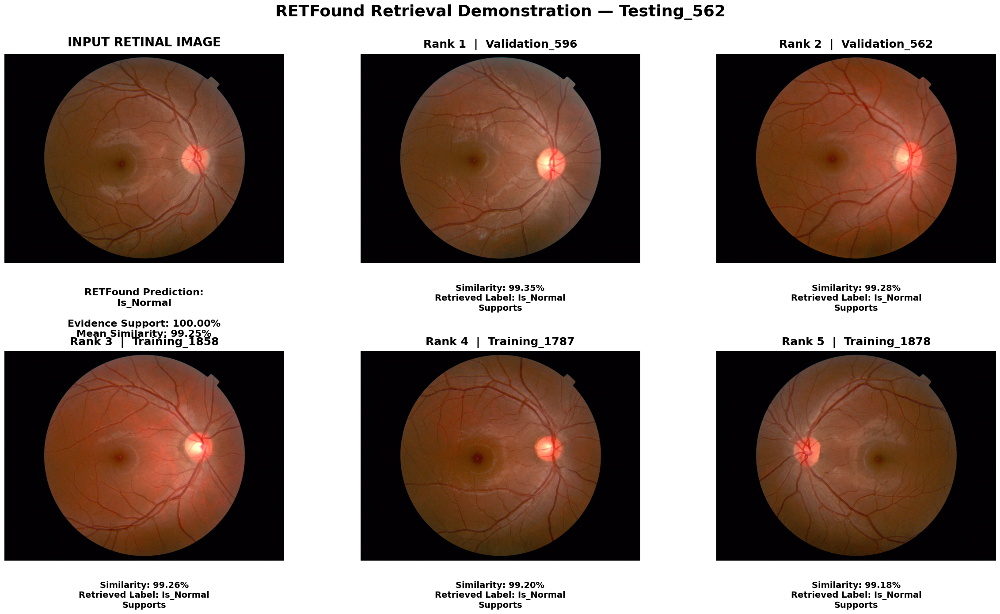

✓ Generated: Testing_562


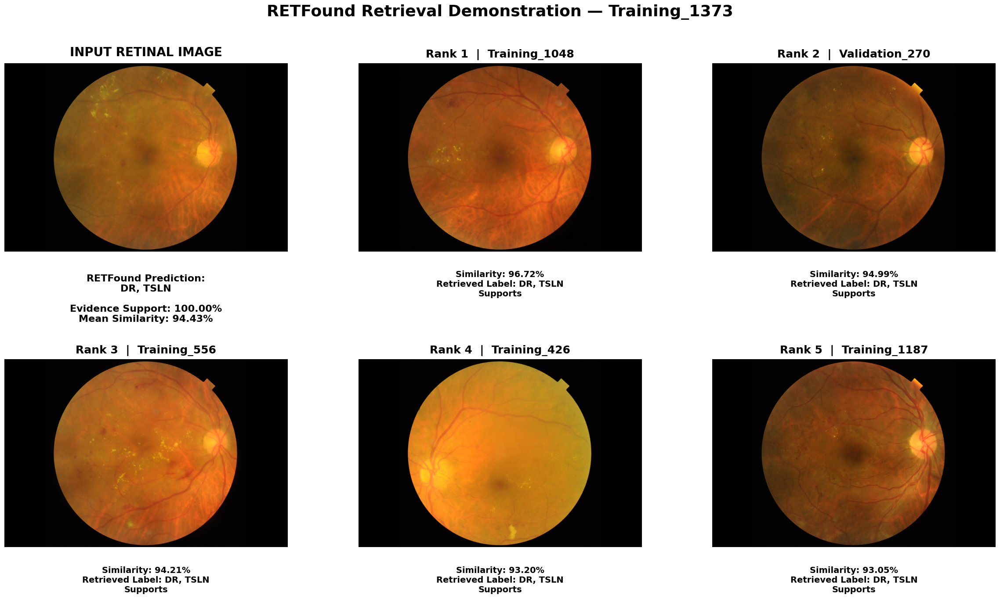

✓ Generated: Training_1373


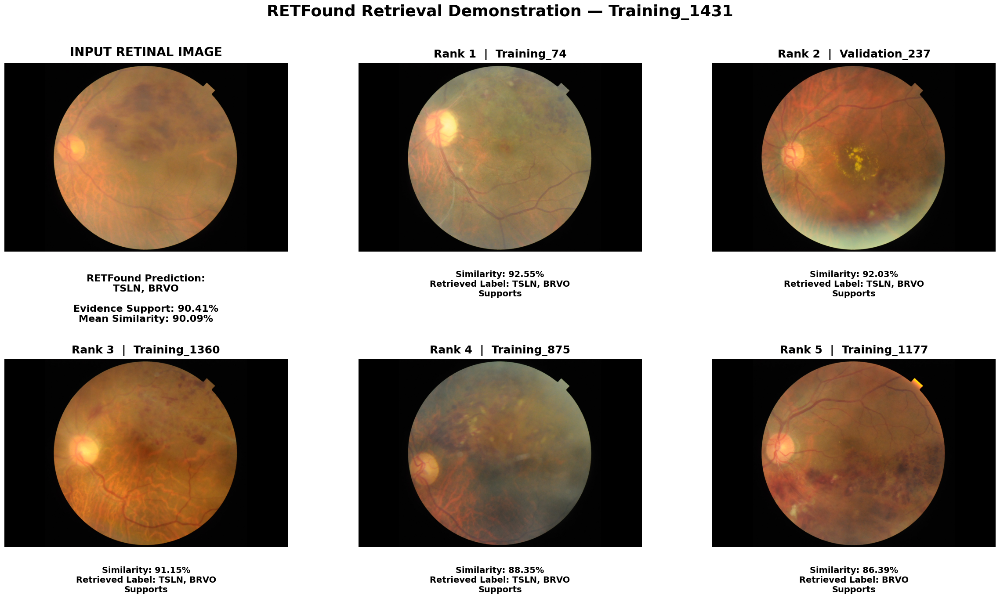

✓ Generated: Training_1431


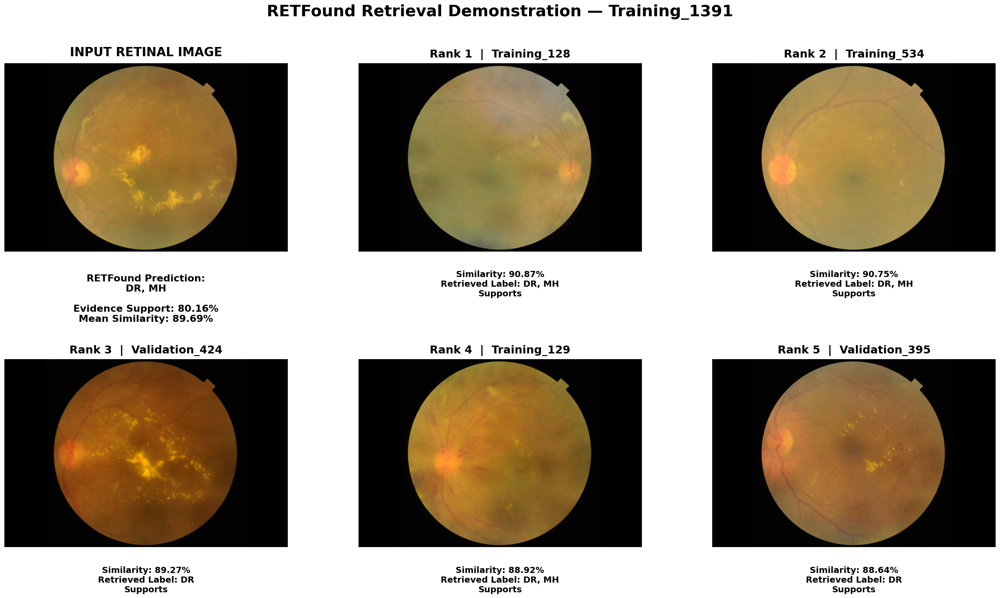

✓ Generated: Training_1391


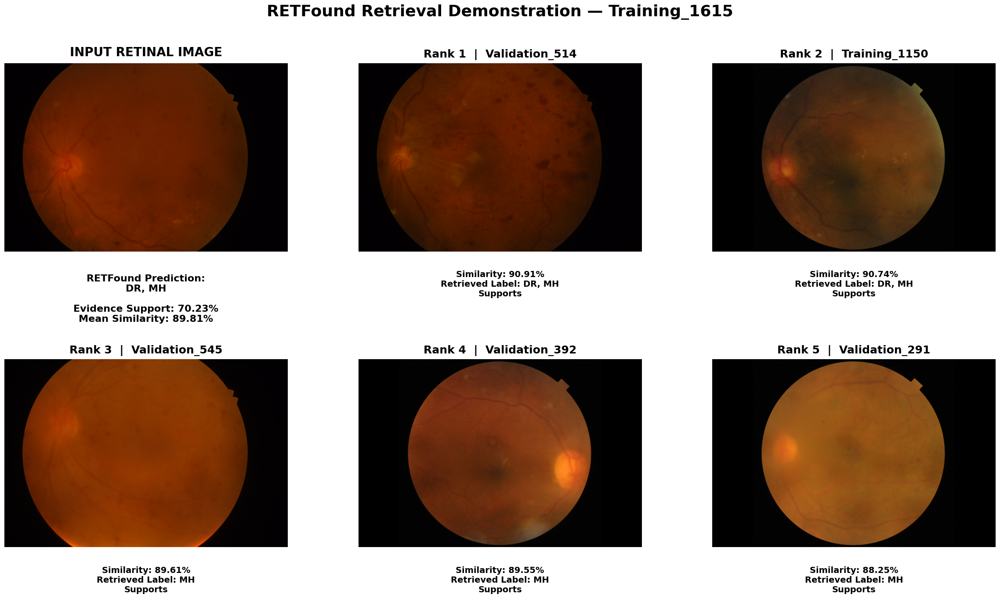

✓ Generated: Training_1615


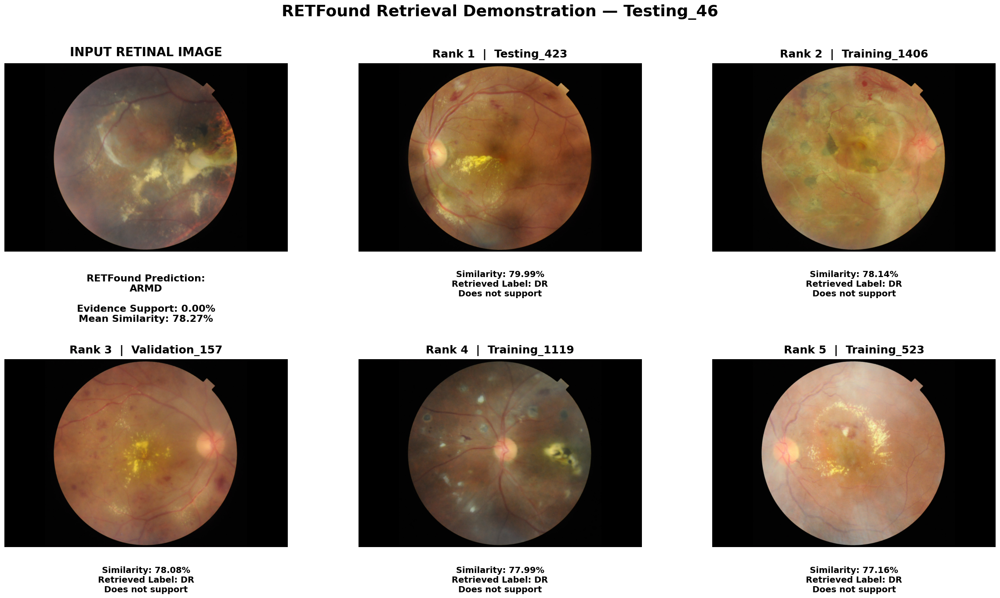

✓ Generated: Testing_46

🎉 ALL 6 DEMONSTRATIONS GENERATED

Output directory:
/kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS

Generated files:
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Testing_562_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1373_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1431_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1391_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1615_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Testing_46_retrieval_demo.png

Total figures: 6


In [39]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ============================================================
# PATHS
# ============================================================

BASE = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"
DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

SUMMARY_FILE = os.path.join(
    BASE, "doctor_facing_retrieval_summary.csv"
)

EVIDENCE_FILE = os.path.join(
    BASE, "doctor_facing_retrieval_evidence.csv"
)

OUTPUT_DIR = "/kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# LOAD RESULT FILES
# ============================================================

summary = pd.read_csv(SUMMARY_FILE)
evidence = pd.read_csv(EVIDENCE_FILE)

# ============================================================
# SIX FINAL DEMONSTRATION CASES
# ============================================================

demo_cases = [
    "Testing_562",
    "Training_1373",
    "Training_1431",
    "Training_1391",
    "Training_1615",
    "Testing_46"
]

# ============================================================
# RETRIEVED IMAGE IDs
# ============================================================

demo_retrievals = {
    "Testing_562": [
        "Validation_596",
        "Validation_562",
        "Training_1858",
        "Training_1787",
        "Training_1878"
    ],

    "Training_1373": [
        "Training_1048",
        "Validation_270",
        "Training_556",
        "Training_426",
        "Training_1187"
    ],

    "Training_1431": [
        "Training_74",
        "Validation_237",
        "Training_1360",
        "Training_875",
        "Training_1177"
    ],

    "Training_1391": [
        "Training_128",
        "Training_534",
        "Validation_424",
        "Training_129",
        "Validation_395"
    ],

    "Training_1615": [
        "Validation_514",
        "Training_1150",
        "Validation_545",
        "Validation_392",
        "Validation_291"
    ],

    "Testing_46": [
        "Testing_423",
        "Training_1406",
        "Validation_157",
        "Training_1119",
        "Training_523"
    ]
}

# ============================================================
# FIND IMAGE PATHS
# ============================================================

required_ids = set(demo_cases)

for ids in demo_retrievals.values():
    required_ids.update(ids)

image_paths = {}

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        ext = os.path.splitext(filename)[1].lower()

        if ext not in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]:
            continue

        image_id = os.path.splitext(filename)[0]

        if image_id in required_ids:
            image_paths[image_id] = os.path.join(root, filename)

# Safety check
missing = sorted(required_ids - set(image_paths))

assert len(missing) == 0, f"Missing images: {missing}"
assert len(image_paths) == 36

print("=" * 80)
print("CREATING FINAL 6-CASE RETRIEVAL DEMONSTRATIONS")
print("=" * 80)

# ============================================================
# GENERATE ONE FIGURE PER CASE
# ============================================================

generated_files = []

for case in demo_cases:

    # --------------------------------------------------------
    # Get summary information
    # --------------------------------------------------------

    summary_row = summary[
        summary["Test_Image_Key"] == case
    ].iloc[0]

    prediction = str(summary_row["RETFound_Prediction"])
    evidence_support = float(summary_row["Evidence_Support_%"])
    mean_similarity = float(summary_row["Mean_Similarity_%"])

    # --------------------------------------------------------
    # Get retrieval information
    # --------------------------------------------------------

    case_evidence = evidence[
        evidence["Test_Image_Key"] == case
    ].sort_values("Rank").copy()

    assert len(case_evidence) == 5

    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2, 3,
        figsize=(24, 14)
    )

    fig.suptitle(
        f"RETFound Retrieval Demonstration — {case}",
        fontsize=26,
        fontweight="bold",
        y=0.98
    )

    # --------------------------------------------------------
    # Input image
    # --------------------------------------------------------

    input_ax = axes[0, 0]

    input_img = Image.open(
        image_paths[case]
    ).convert("RGB")

    input_ax.imshow(input_img)
    input_ax.axis("off")

    input_ax.set_title(
        "INPUT RETINAL IMAGE",
        fontsize=20,
        fontweight="bold",
        pad=12
    )

    # --------------------------------------------------------
    # Prediction information
    # --------------------------------------------------------

    input_ax.text(
        0.5,
        -0.12,
        f"RETFound Prediction:\n{prediction}\n\n"
        f"Evidence Support: {evidence_support:.2f}%\n"
        f"Mean Similarity: {mean_similarity:.2f}%",
        transform=input_ax.transAxes,
        ha="center",
        va="top",
        fontsize=16,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Five retrieved images
    # --------------------------------------------------------

    for idx, (_, row) in enumerate(case_evidence.iterrows()):

        # Map retrieval rank to subplot
        if idx == 0:
            ax = axes[0, 1]
        elif idx == 1:
            ax = axes[0, 2]
        elif idx == 2:
            ax = axes[1, 0]
        elif idx == 3:
            ax = axes[1, 1]
        else:
            ax = axes[1, 2]

        retrieved_id = str(
            row["Retrieved_Image_Key"]
        )

        similarity = float(
            row["Similarity"]
        ) * 100

        retrieved_labels = str(
            row["Retrieved_Labels"]
        )

        support_status = str(
            row["Support_Status"]
        )

        # ----------------------------------------------------
        # Display retrieved image
        # ----------------------------------------------------

        retrieved_img = Image.open(
            image_paths[retrieved_id]
        ).convert("RGB")

        ax.imshow(retrieved_img)
        ax.axis("off")

        ax.set_title(
            f"Rank {int(row['Rank'])}  |  {retrieved_id}",
            fontsize=18,
            fontweight="bold",
            pad=10
        )

        # ----------------------------------------------------
        # Retrieval information
        # ----------------------------------------------------

        ax.text(
            0.5,
            -0.10,
            f"Similarity: {similarity:.2f}%\n"
            f"Retrieved Label: {retrieved_labels}\n"
            f"{support_status}",
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=14,
            fontweight="bold"
        )

    # --------------------------------------------------------
    # Layout
    # --------------------------------------------------------

    plt.subplots_adjust(
        left=0.03,
        right=0.97,
        top=0.90,
        bottom=0.08,
        wspace=0.25,
        hspace=0.42
    )

    # --------------------------------------------------------
    # Save figure
    # --------------------------------------------------------

    output_file = os.path.join(
        OUTPUT_DIR,
        f"{case}_retrieval_demo.png"
    )

    plt.savefig(
        output_file,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    generated_files.append(output_file)

    print(f"✓ Generated: {case}")

# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 80)
print("🎉 ALL 6 DEMONSTRATIONS GENERATED")
print("=" * 80)

print(f"\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for f in generated_files:
    print(" ", f)

print(f"\nTotal figures: {len(generated_files)}")

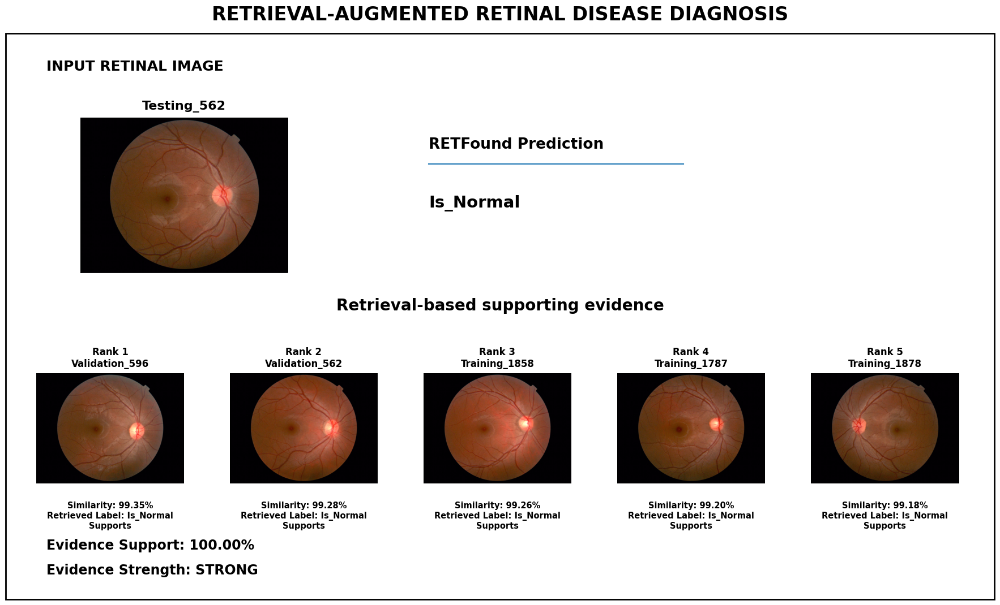

✓ Generated Testing_562


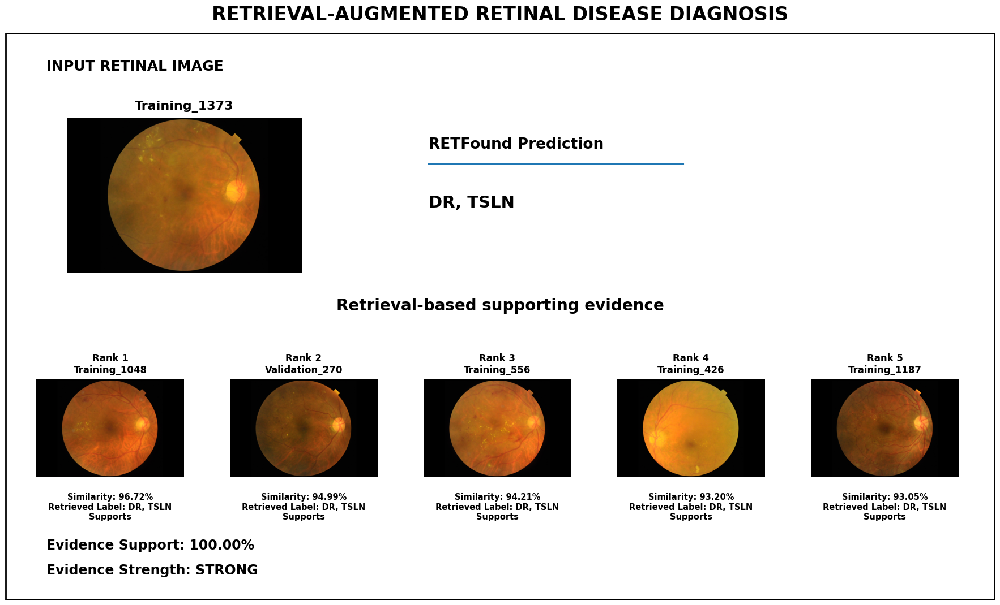

✓ Generated Training_1373


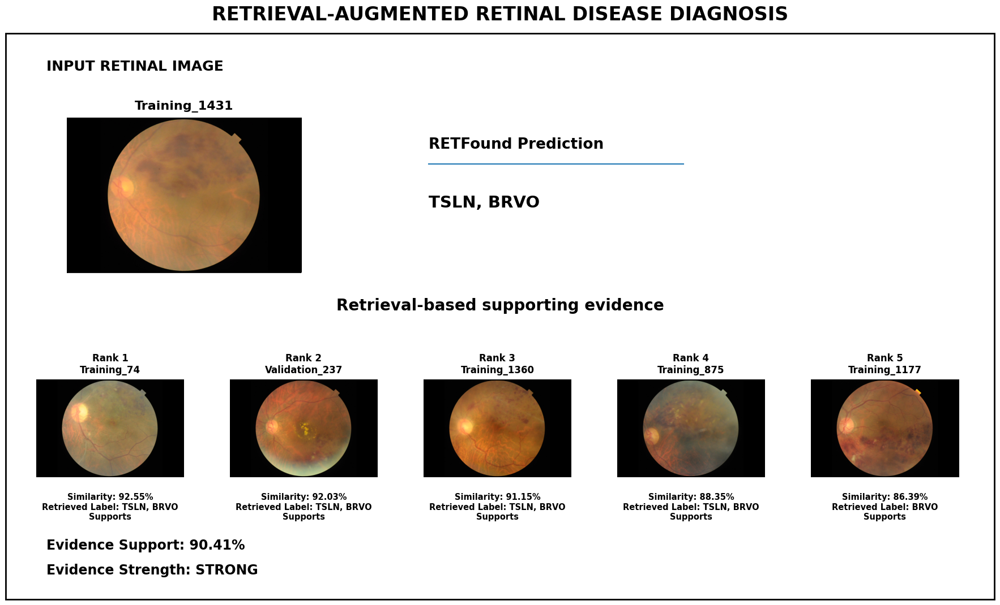

✓ Generated Training_1431


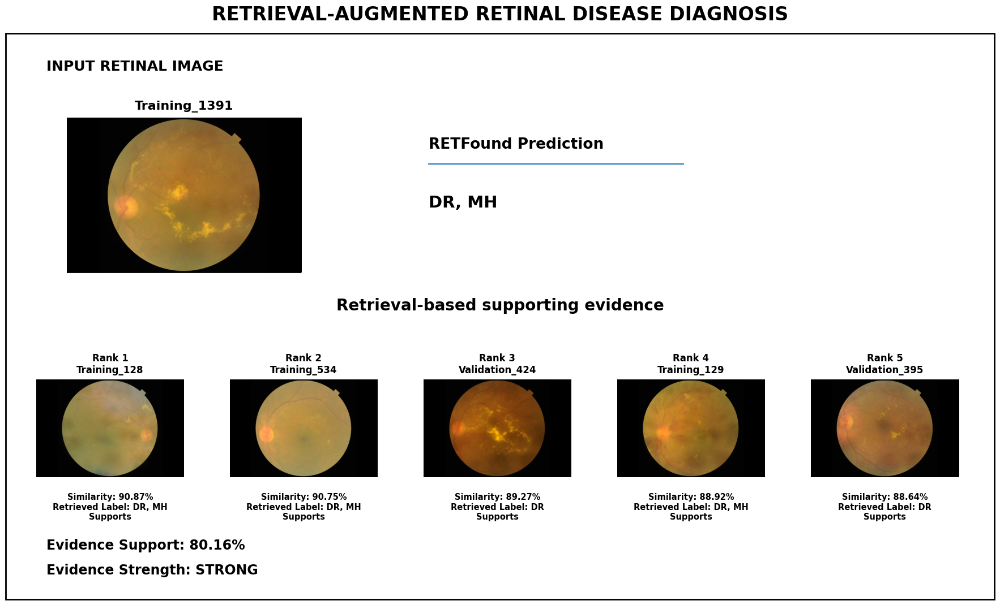

✓ Generated Training_1391


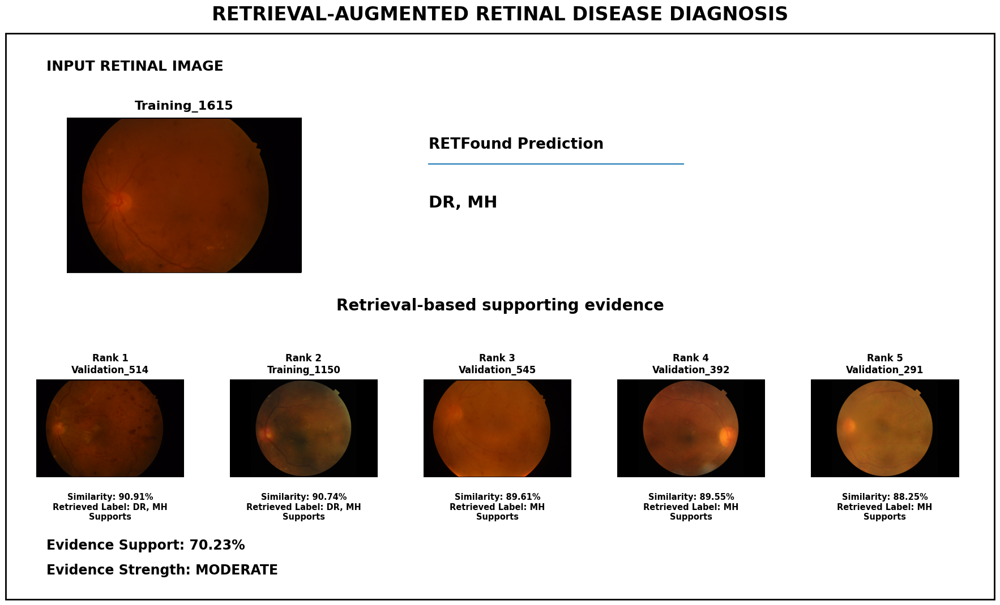

✓ Generated Training_1615


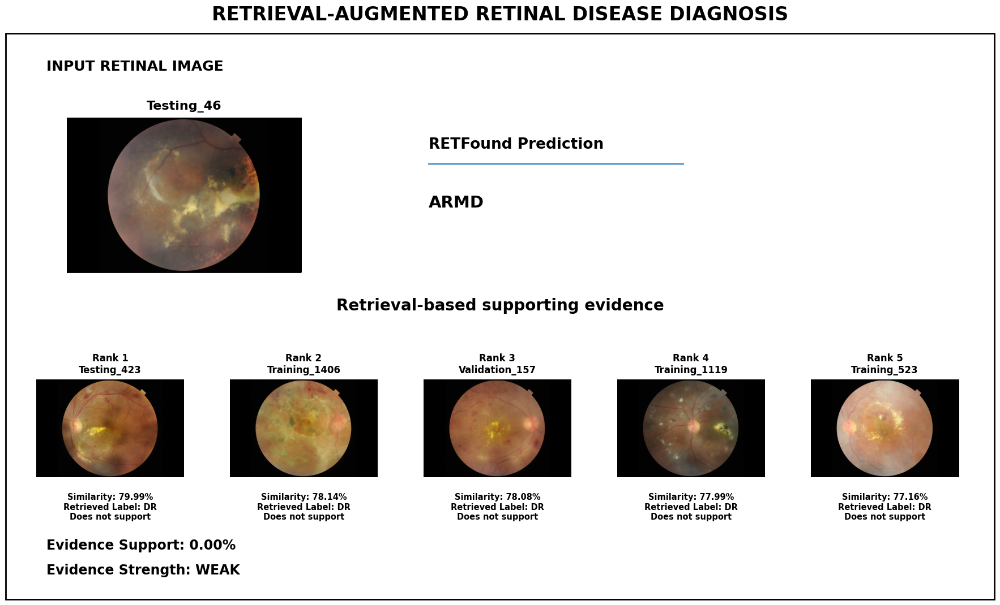

✓ Generated Testing_46

🎉 FINAL PRESENTATION-STYLE DEMONSTRATIONS CREATED

Output folder:
/kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS

Files:
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Testing_562_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1373_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1431_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1391_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Training_1615_retrieval_demo.png
  /kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS/Testing_46_retrieval_demo.png


In [40]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle

# ============================================================
# PATHS
# ============================================================

BASE = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"
DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

SUMMARY_FILE = os.path.join(
    BASE, "doctor_facing_retrieval_summary.csv"
)

EVIDENCE_FILE = os.path.join(
    BASE, "doctor_facing_retrieval_evidence.csv"
)

OUTPUT_DIR = "/kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# LOAD RESULTS
# ============================================================

summary = pd.read_csv(SUMMARY_FILE)
evidence = pd.read_csv(EVIDENCE_FILE)

# ============================================================
# FINAL 6 DEMONSTRATION CASES
# ============================================================

demo_cases = [
    "Testing_562",
    "Training_1373",
    "Training_1431",
    "Training_1391",
    "Training_1615",
    "Testing_46"
]

# ============================================================
# EXACT TOP-5 RETRIEVALS
# ============================================================

demo_retrievals = {
    "Testing_562": [
        "Validation_596",
        "Validation_562",
        "Training_1858",
        "Training_1787",
        "Training_1878"
    ],

    "Training_1373": [
        "Training_1048",
        "Validation_270",
        "Training_556",
        "Training_426",
        "Training_1187"
    ],

    "Training_1431": [
        "Training_74",
        "Validation_237",
        "Training_1360",
        "Training_875",
        "Training_1177"
    ],

    "Training_1391": [
        "Training_128",
        "Training_534",
        "Validation_424",
        "Training_129",
        "Validation_395"
    ],

    "Training_1615": [
        "Validation_514",
        "Training_1150",
        "Validation_545",
        "Validation_392",
        "Validation_291"
    ],

    "Testing_46": [
        "Testing_423",
        "Training_1406",
        "Validation_157",
        "Training_1119",
        "Training_523"
    ]
}

# ============================================================
# FIND IMAGE PATHS
# ============================================================

required_ids = set(demo_cases)

for ids in demo_retrievals.values():
    required_ids.update(ids)

image_paths = {}

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        ext = os.path.splitext(filename)[1].lower()

        if ext not in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]:
            continue

        image_id = os.path.splitext(filename)[0]

        if image_id in required_ids:
            image_paths[image_id] = os.path.join(
                root, filename
            )

missing = sorted(required_ids - set(image_paths.keys()))

assert len(missing) == 0, f"Missing images: {missing}"

# ============================================================
# GENERATE FIGURES
# ============================================================

generated_files = []

for case in demo_cases:

    # --------------------------------------------------------
    # Summary information
    # --------------------------------------------------------

    row = summary[
        summary["Test_Image_Key"] == case
    ].iloc[0]

    prediction = str(row["RETFound_Prediction"])
    evidence_support = float(row["Evidence_Support_%"])

    # Evidence strength
    if evidence_support >= 80:
        evidence_strength = "STRONG"
    elif evidence_support >= 60:
        evidence_strength = "MODERATE"
    else:
        evidence_strength = "WEAK"

    # --------------------------------------------------------
    # Retrieval information
    # --------------------------------------------------------

    case_evidence = evidence[
        evidence["Test_Image_Key"] == case
    ].sort_values("Rank").copy()

    assert len(case_evidence) == 5

    # --------------------------------------------------------
    # FIGURE
    # --------------------------------------------------------

    fig = plt.figure(figsize=(18, 11))

    # Main title
    fig.text(
        0.5,
        0.965,
        "RETRIEVAL-AUGMENTED RETINAL DISEASE DIAGNOSIS",
        ha="center",
        va="center",
        fontsize=24,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Outer border
    # --------------------------------------------------------

    outer = Rectangle(
        (0.015, 0.025),
        0.97,
        0.91,
        fill=False,
        linewidth=2
    )

    fig.add_artist(outer)

    # --------------------------------------------------------
    # SECTION: INPUT RETINAL IMAGE
    # --------------------------------------------------------

    fig.text(
        0.055,
        0.875,
        "INPUT RETINAL IMAGE",
        fontsize=18,
        fontweight="bold"
    )

    # Input image area
    input_ax = fig.add_axes(
        [0.065, 0.55, 0.25, 0.25]
    )

    input_img = Image.open(
        image_paths[case]
    ).convert("RGB")

    input_ax.imshow(input_img)
    input_ax.axis("off")

    # Border around input
    input_border = Rectangle(
        (0, 0),
        1,
        1,
        transform=input_ax.transAxes,
        fill=False,
        linewidth=2
    )

    input_ax.add_patch(input_border)

    input_ax.set_title(
        case,
        fontsize=16,
        fontweight="bold",
        pad=10
    )

    # --------------------------------------------------------
    # RETFound PREDICTION
    # --------------------------------------------------------

    fig.text(
        0.43,
        0.75,
        "RETFound Prediction",
        fontsize=19,
        fontweight="bold"
    )

    # underline
    fig.add_artist(
        plt.Line2D(
            [0.43, 0.68],
            [0.725, 0.725],
            transform=fig.transFigure,
            linewidth=1.5
        )
    )

    fig.text(
        0.43,
        0.655,
        prediction,
        fontsize=21,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # RETRIEVAL SECTION
    # --------------------------------------------------------

    fig.text(
        0.5,
        0.49,
        "Retrieval-based supporting evidence",
        ha="center",
        fontsize=20,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # FIVE RETRIEVED IMAGES
    # --------------------------------------------------------

    x_positions = [
        0.045,
        0.235,
        0.425,
        0.615,
        0.805
    ]

    for idx, (_, retrieval_row) in enumerate(
        case_evidence.iterrows()
    ):

        retrieved_id = str(
            retrieval_row["Retrieved_Image_Key"]
        )

        similarity = float(
            retrieval_row["Similarity"]
        ) * 100

        retrieved_labels = str(
            retrieval_row["Retrieved_Labels"]
        )

        support_status = str(
            retrieval_row["Support_Status"]
        )

        # Image axis
        ax = fig.add_axes(
            [
                x_positions[idx],
                0.19,
                0.145,
                0.22
            ]
        )

        retrieved_img = Image.open(
            image_paths[retrieved_id]
        ).convert("RGB")

        ax.imshow(retrieved_img)
        ax.axis("off")

        # Border
        border = Rectangle(
            (0, 0),
            1,
            1,
            transform=ax.transAxes,
            fill=False,
            linewidth=2
        )

        ax.add_patch(border)

        # Rank + ID
        ax.set_title(
            f"Rank {int(retrieval_row['Rank'])}\n"
            f"{retrieved_id}",
            fontsize=12,
            fontweight="bold",
            pad=8
        )

        # Information below image
        ax.text(
            0.5,
            -0.16,
            f"Similarity: {similarity:.2f}%\n"
            f"Retrieved Label: {retrieved_labels}\n"
            f"{support_status}",
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=10.5,
            fontweight="bold"
        )

    # --------------------------------------------------------
    # FINAL EVIDENCE INFORMATION
    # --------------------------------------------------------

    fig.text(
        0.055,
        0.105,
        f"Evidence Support: {evidence_support:.2f}%",
        fontsize=17,
        fontweight="bold"
    )

    fig.text(
        0.055,
        0.065,
        f"Evidence Strength: {evidence_strength}",
        fontsize=17,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    output_file = os.path.join(
        OUTPUT_DIR,
        f"{case}_retrieval_demo.png"
    )

    plt.savefig(
        output_file,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    generated_files.append(output_file)

    print(f"✓ Generated {case}")

# ============================================================
# FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("🎉 FINAL PRESENTATION-STYLE DEMONSTRATIONS CREATED")
print("=" * 80)

print(f"\nOutput folder:")
print(OUTPUT_DIR)

print("\nFiles:")

for file in generated_files:
    print(" ", file)

In [41]:
import os
import zipfile

DEMO_DIR = "/kaggle/working/PROJECT_PHASE_1_DEMONSTRATIONS"
ZIP_PATH = "/kaggle/working/PROJECT_PHASE_1_6_CASE_DEMONSTRATIONS.zip"

# Expected six figures
expected_files = [
    "Testing_562_retrieval_demo.png",
    "Training_1373_retrieval_demo.png",
    "Training_1431_retrieval_demo.png",
    "Training_1391_retrieval_demo.png",
    "Training_1615_retrieval_demo.png",
    "Testing_46_retrieval_demo.png"
]

print("=" * 80)
print("VERIFYING AND PACKAGING FINAL 6 DEMONSTRATIONS")
print("=" * 80)

# ------------------------------------------------------------
# Verify all six figures exist
# ------------------------------------------------------------

missing = []

for filename in expected_files:
    path = os.path.join(DEMO_DIR, filename)

    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"✓ {filename} ({size_kb:.1f} KB)")
    else:
        missing.append(filename)

assert not missing, f"Missing figures: {missing}"

# ------------------------------------------------------------
# Create ZIP
# ------------------------------------------------------------

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for filename in expected_files:
        path = os.path.join(DEMO_DIR, filename)
        zipf.write(path, arcname=filename)

# ------------------------------------------------------------
# Verify ZIP
# ------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
    zip_contents = zipf.namelist()

print("\n" + "=" * 80)
print("ZIP CONTENTS")
print("=" * 80)

for filename in zip_contents:
    print("✓", filename)

assert len(zip_contents) == 6

print("\n" + "=" * 80)
print("🎉 FINAL 6-CASE DEMONSTRATION PACKAGE CREATED")
print("=" * 80)

print(f"\nZIP file:")
print(ZIP_PATH)

print(f"Size: {os.path.getsize(ZIP_PATH) / 1024:.1f} KB")
print("\nTotal figures:", len(zip_contents))

VERIFYING AND PACKAGING FINAL 6 DEMONSTRATIONS
✓ Testing_562_retrieval_demo.png (1642.2 KB)
✓ Training_1373_retrieval_demo.png (1235.6 KB)
✓ Training_1431_retrieval_demo.png (1259.2 KB)
✓ Training_1391_retrieval_demo.png (1220.4 KB)
✓ Training_1615_retrieval_demo.png (1292.1 KB)
✓ Testing_46_retrieval_demo.png (1263.3 KB)

ZIP CONTENTS
✓ Testing_562_retrieval_demo.png
✓ Training_1373_retrieval_demo.png
✓ Training_1431_retrieval_demo.png
✓ Training_1391_retrieval_demo.png
✓ Training_1615_retrieval_demo.png
✓ Testing_46_retrieval_demo.png

🎉 FINAL 6-CASE DEMONSTRATION PACKAGE CREATED

ZIP file:
/kaggle/working/PROJECT_PHASE_1_6_CASE_DEMONSTRATIONS.zip
Size: 7604.4 KB

Total figures: 6
